# Corrected reruns (380/381/382) vs the seed-287 RefleX test set
Same as `analysis_corrected.ipynb`, but the RefleX test reference (`REFLEX_NPZ`) is the independent seed-287 realization of the 225-point test grid (`npy_data/testing_dataset_allscat_seed_287/`) instead of `RefleX_Dataset_8_Testing`. Outputs go to `npz_data_corrected_seed287/`.

# Model testing with photon count matrices

In [1]:
from utils.io_npy import *
from utils.io_npz import *
from utils.error_functions import *
from utils.plotting import *
from utils.heatmaps import *
from utils.grids import *
from utils.metrics import *


import numpy as np

In [2]:
# some global parameters

NBINS = 24
BIN_FILTER = 10.0


To see how we divide an image to radial bins.

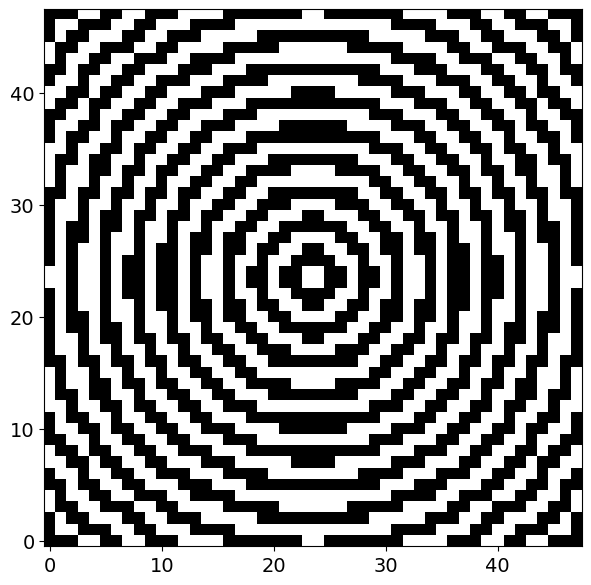

(array([[23, 23, 23, ..., 23, 23, 23],
        [23, 22, 22, ..., 22, 22, 23],
        [23, 22, 21, ..., 21, 22, 23],
        ...,
        [23, 22, 21, ..., 21, 22, 23],
        [23, 22, 22, ..., 22, 22, 23],
        [23, 23, 23, ..., 23, 23, 23]]),
 array([ 0.        ,  1.38475078,  2.76950156,  4.15425234,  5.53900312,
         6.9237539 ,  8.30850468,  9.69325546, 11.07800624, 12.46275702,
        13.8475078 , 15.23225858, 16.61700936, 18.00176014, 19.38651092,
        20.7712617 , 22.15601248, 23.54076326, 24.92551404, 26.31026482,
        27.6950156 , 29.07976638, 30.46451716, 31.84926794, 33.23401872]))

In [3]:
plot_radial_bins(n_annuli=24,font_size=14)

In [4]:
npy_dir = "./npy_data/"
npz_dir = "./npz_data_corrected_seed287/"  # corrected reruns 380-382, evaluated against the independent seed-287 RefleX test set
used_dataset = "" #  dataset for testing

sampling_type = "DDPM" # can be DDPM or DDIM, check if samples exist for the type

REFLEX_PATH = f"{npy_dir}testing_dataset_allscat_seed_287/"  # independent seed-287 test realization #  dataset for testing
REFLEX_PATH_TRAINING = f"{npy_dir}RefleX_Dataset_8_Training/"
REFLEX_NPZ = f"{npz_dir}REFLEX.npz"
REFLEX_NPZ_TRAINING = f"{npz_dir}REFLEX_TRAINING.npz"

MODEL_A_NPZ = f"{npz_dir}MODEL_A.npz"
MODEL_B_NPZ = f"{npz_dir}MODEL_B.npz"
MODEL_C_NPZ = f"{npz_dir}MODEL_C.npz"
MODEL_D_NPZ = f"{npz_dir}MODEL_D.npz"  # blackout diffusion (run 379)

exclude_nH = [] # List of nH values we will exclude.
if used_dataset == "3_extended":
    exclude_nH = [1e8, 1e9, 1e10, 1e11, 1e12, 1e13, 1e14, 1e15, 
                  1e16, 1e17, 1e18, 1e19, 3.46e17, 4.64e19, 4.64e23, 1e24]

exclude_x = [] # List of x values we will exclude.
if used_dataset == "3_extended":
    exclude_x = []


save_npy_to_npz(REFLEX_PATH, out_path=REFLEX_NPZ, pattern="*.npy", exclude_nH=exclude_nH, exclude_x = exclude_x ,k = 1.0, resize_to_48=False)
save_npy_to_npz(REFLEX_PATH_TRAINING, out_path=REFLEX_NPZ_TRAINING, pattern="*.npy", exclude_nH=exclude_nH, exclude_x = exclude_x ,k = 1.0, resize_to_48=False)


Saved 225 matrices to ./npz_data_corrected_seed287/REFLEX.npz with shape (48, 48) + dmin/dmax arrays.


Saved 1024 matrices to ./npz_data_corrected_seed287/REFLEX_TRAINING.npz with shape (48, 48) + dmin/dmax arrays.


Saving the samples from each checkpoint from each model to an npz file

In [5]:
checkpoint_lists = {
    "A": ["01","02","03","04","05","06","07","08","09","10","11","12","13","14","15","16","17","18","19","20"],
    "B": ["01","02","03","04","05","06","07","08","09","10","11","12","13","14","15","16","17","18","19","20"],
    "C": ["01","02","03","04","05","06","07","08","09","10","11","12","13","14","15","16","17","18","19","20"],
    "D": ["01","02","03","04","05","06","07","08","09","10","11","12","15","20"],
}

model_names = {
    "A": lambda cp: f"380_Model_A_Corrected_model_A_{cp}k_{sampling_type}",
    "B": lambda cp: f"381_Model_B_Corrected_model_B_{cp}k_{sampling_type}", # 0-0 bin filtering in aux loss
    "C": lambda cp: f"382_Model_C_Corrected_model_C_{cp}k_{sampling_type}",
    "D": lambda cp: f"379_Blackout_Diffusion_{cp}k_BLACKOUT",
}

# "C": lambda cp: f"374_Aux_Poisson_Deviance_No_Validation_N_Fitted_Aux_{cp}k_{sampling_type}",
model_npz_paths = {"A": MODEL_A_NPZ, "B": MODEL_B_NPZ, "C": MODEL_C_NPZ, "D": MODEL_D_NPZ}
results = {model: ([], []) for model in model_names}
metric_kwargs = {"n_annuli": 24, "pixel_scale_arcsec": 45.0}
metric_kwargs_chi2 = {
    "n_annuli": 24,
    "pixel_scale_arcsec": 45.0,
    "Fano_Data": 1,
    "Fano_Model": 1,
    "use_N": False,
    "bin_filter": 10,
}

metric = "pois"
for model, make_name in model_names.items():
    for cpnt in checkpoint_lists[model]:
        save_npy_to_npz(
            f"{npy_dir}{make_name(cpnt)}",
            out_path=model_npz_paths[model], checkpoint=cpnt, pattern="*.npy",
            exclude_nH=exclude_nH, exclude_x=exclude_x, k=1.0,
        )
        if metric == "pois":
            mean_error, error_std = mean_error_between_npz(
                npz_model_path=f"{npz_dir}MODEL_{model}_{cpnt}k.npz",
                npz_data_path=REFLEX_NPZ,
                error_func=radial_reduced_poisson_deviance_abs,
                err_kwargs=metric_kwargs,
            )
        if metric == "chi2":
            mean_error, error_std = mean_error_between_npz(
                npz_model_path=f"{npz_dir}MODEL_{model}_{cpnt}k.npz",
                npz_data_path=REFLEX_NPZ,
                error_func=radial_reduced_chi2_area2_bin_filtered,
                err_kwargs=metric_kwargs_chi2,
            )
        results[model][0].append(mean_error)
        results[model][1].append(error_std)

Model_A_Mean_Errors, Model_A_Error_Stds = results["A"]
Model_B_Mean_Errors, Model_B_Error_Stds = results["B"]
Model_C_Mean_Errors, Model_C_Error_Stds = results["C"]
Model_D_Mean_Errors, Model_D_Error_Stds = results["D"]


Saved 225 matrices to ./npz_data_corrected_seed287/MODEL_A_01k.npz with shape (48, 48) + dmin/dmax arrays.


Saved 225 matrices to ./npz_data_corrected_seed287/MODEL_A_02k.npz with shape (48, 48) + dmin/dmax arrays.


Saved 225 matrices to ./npz_data_corrected_seed287/MODEL_A_03k.npz with shape (48, 48) + dmin/dmax arrays.


Saved 225 matrices to ./npz_data_corrected_seed287/MODEL_A_04k.npz with shape (48, 48) + dmin/dmax arrays.


Saved 225 matrices to ./npz_data_corrected_seed287/MODEL_A_05k.npz with shape (48, 48) + dmin/dmax arrays.


Saved 225 matrices to ./npz_data_corrected_seed287/MODEL_A_06k.npz with shape (48, 48) + dmin/dmax arrays.


... (64 outputs left out)

Saved 225 matrices to ./npz_data_corrected_seed287/MODEL_D_11k.npz with shape (48, 48) + dmin/dmax arrays.


Saved 225 matrices to ./npz_data_corrected_seed287/MODEL_D_12k.npz with shape (48, 48) + dmin/dmax arrays.


Saved 225 matrices to ./npz_data_corrected_seed287/MODEL_D_15k.npz with shape (48, 48) + dmin/dmax arrays.


Saved 225 matrices to ./npz_data_corrected_seed287/MODEL_D_20k.npz with shape (48, 48) + dmin/dmax arrays.


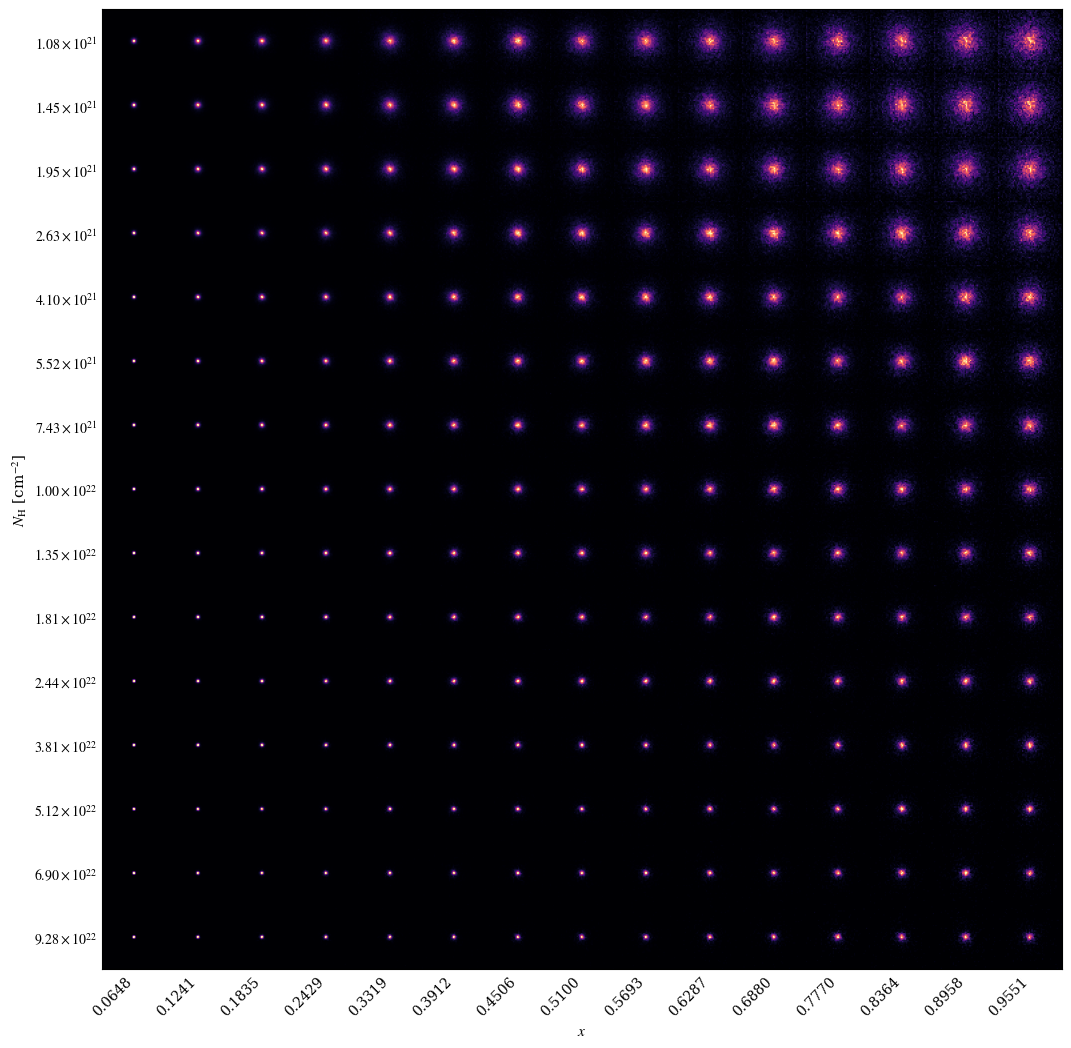

In [6]:
plot_matrix_grid(npz_path="./npz_data_corrected_seed287/MODEL_D_06k.npz",
                 figsize=(12,12))
plt.show()


In [7]:
seed_list = [45, 107, 115, 284, 334]  # replace with your seeds

for seed in seed_list:
    custom_npy_pth = (
        f"{npy_dir}"
        f"RefleX_Different_Seed_Grid_Increased_Camera_Center_Distance/"
        f"seed_{seed}/npy"
    )

    save_npy_to_npz(
        custom_npy_pth,
        out_path=f"{npz_dir}seed_{seed}.npz",
        checkpoint="00",
        pattern="*.npy",
        exclude_nH=[1e24],
        exclude_x=exclude_x,
        k=1.0,
    )

Saved 12 matrices to ./npz_data_corrected_seed287/seed_45_00k.npz with shape (50, 50) + dmin/dmax arrays. Skipped 4 due to exclude_nH=[1e+24] (tol=0.0).
Saved 12 matrices to ./npz_data_corrected_seed287/seed_107_00k.npz with shape (50, 50) + dmin/dmax arrays. Skipped 4 due to exclude_nH=[1e+24] (tol=0.0).
Saved 12 matrices to ./npz_data_corrected_seed287/seed_115_00k.npz with shape (50, 50) + dmin/dmax arrays. Skipped 4 due to exclude_nH=[1e+24] (tol=0.0).
Saved 12 matrices to ./npz_data_corrected_seed287/seed_284_00k.npz with shape (50, 50) + dmin/dmax arrays. Skipped 4 due to exclude_nH=[1e+24] (tol=0.0).
Saved 12 matrices to ./npz_data_corrected_seed287/seed_334_00k.npz with shape (50, 50) + dmin/dmax arrays. Skipped 4 due to exclude_nH=[1e+24] (tol=0.0).


In [8]:
custom_npy_pth = f"{npy_dir}testing_dataset_singlescat_seed_287/"

save_npy_to_npz(f"{custom_npy_pth}", 
                out_path=f"{npz_dir}testing_dataset_singlescat_seed_287.npz", 
                checkpoint="",
                pattern="*.npy", 
                exclude_nH=exclude_nH, 
                exclude_x = exclude_x,k = 1.0)

TESTING_DATASET_SINGLESCAT = f"{npz_dir}testing_dataset_singlescat_seed_287.npz"

Saved 225 matrices to ./npz_data_corrected_seed287/testing_dataset_singlescat_seed_287.npz with shape (48, 48) + dmin/dmax arrays.


 Summary: Mean pairwise Poisson-deviance grid
 Statistic           : mean pairwise radial two-sample Poisson deviance
 Archives            : 5  (seed_45_00k, seed_107_00k, seed_115_00k, seed_284_00k, seed_334_00k)
 Pairs per cell      : 10
 Grid                : 3 x 4  (12 cells, 12 finite, 0 missing)
 Annuli per image    : 24
 Mean D_red          : 0.9335
 Std (ddof=1)        : 0.2817     SEM: 0.0813
 Median D_red        : 0.9128
 Trimmed mean (10%)  : 0.9218
 Geometric mean      : 0.8940
 IQR                 : 0.8257 - 0.9712
 Percentiles         : p90=1.2685  p95=1.4120  p99=1.5250
 Min / Max           : 0.4309 / 1.5532
 Fraction D_red <= 1.00 :  75.00%  (9/12)
 Fraction D_red <= 2.00 : 100.00%  (12/12)
 Fraction D_red <= 3.00 : 100.00%  (12/12)
------------------------------------------------------------------
 Extremes
   Lowest       0.4309  at x=0.0500, nH=1.000e+20
   Highest      1.5532  at x=0.0500, nH=2.150e+21
   ~Mean        0.9347  at x=0.3566, nH=2.150e+21
   ~Median    

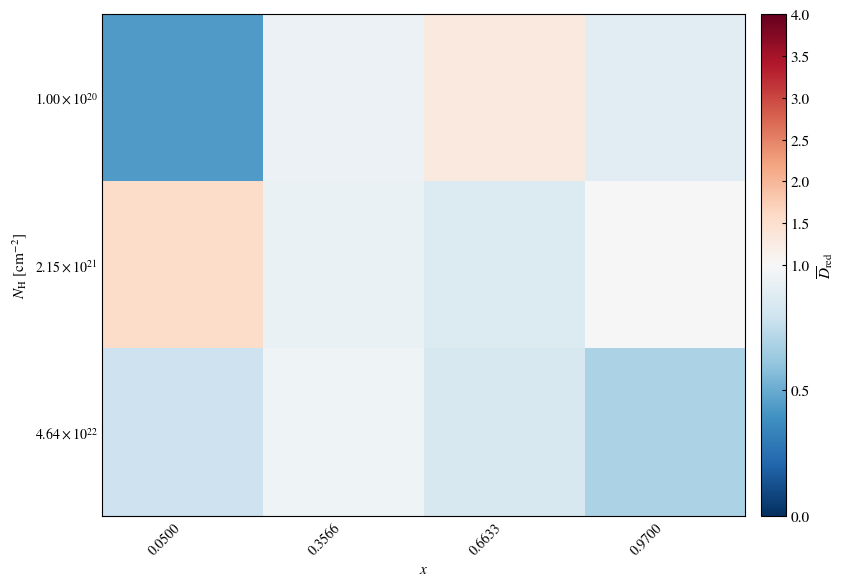

In [9]:
seed_npz_paths = [f"{npz_dir}seed_{seed}_00k.npz" for seed in seed_list]

Error_Heatmap_Mean, xs, nHs = poisson_deviance_heatmap_pairwise_mean_npz(
    seed_npz_paths,
    n_annuli=24,
    diverging=True,
    cmap="magma",
    figsize=(9, 6),
    vmin=0.0,
    vmax=4.0,
    annotate_above=4,
    annotate_fontsize=13,
)


Model A errors:
  Checkpoint 1: 86053.945271
  Checkpoint 2: 78071.188025
  Checkpoint 3: 69085.885461
  Checkpoint 4: 760.581557
  Checkpoint 5: 415.538105
  Checkpoint 6: 149.373017
  Checkpoint 7: 128.142568
  Checkpoint 8: 84.730566
  Checkpoint 9: 178.891916
  Checkpoint 10: 68.951026
  Checkpoint 11: 52.473720
  Checkpoint 12: 77.342023
  Checkpoint 13: 44.136736
  Checkpoint 14: 41.292652
  Checkpoint 15: 49.327345
  Checkpoint 16: 33.373588
  Checkpoint 17: 33.263250
  Checkpoint 18: 23.993112
  Checkpoint 19: 14.313237
  Checkpoint 20: 27.643429

Model B errors:
  Checkpoint 1: 50839.982019
  Checkpoint 2: 48804.276876
  Checkpoint 3: 45750.231623
  Checkpoint 4: 577.649634
  Checkpoint 5: 8.701674
  Checkpoint 6: 6.398395
  Checkpoint 7: 5.458095
  Checkpoint 8: 4.156412
  Checkpoint 9: 2.730589
  Checkpoint 10: 3.055782
  Checkpoint 11: 4.351079
  Checkpoint 12: 3.505854
  Checkpoint 13: 2.095024
  Checkpoint 14: 2.270314
  Checkpoint 15: 2.359134
  Checkpoint 16: 2.186465


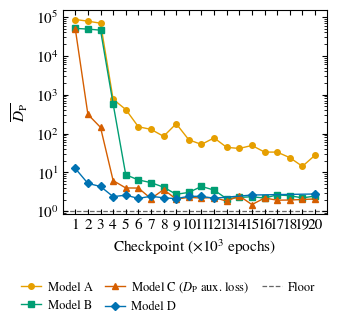

In [10]:
import numpy as np
import matplotlib.pyplot as plt

JOURNAL_RC = {
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 11,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "xtick.minor.size": 2.0,
    "ytick.minor.size": 2.0,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "axes.linewidth": 0.8,
    "legend.frameon": False,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
}

x_A = np.array([int(c) for c in checkpoint_lists["A"]])
x_B = np.array([int(c) for c in checkpoint_lists["B"]])
x_C = np.array([int(c) for c in checkpoint_lists["C"]])
x_D = np.array([int(c) for c in checkpoint_lists["D"]])
x_all_ticks = np.array(sorted(set(x_A) | set(x_B) | set(x_C) | set(x_D)))

with plt.rc_context(JOURNAL_RC):
    fig, ax = plt.subplots(figsize=(3.5, 2.8))

    ax.plot(
        x_A, Model_A_Mean_Errors,
        marker="o", markersize=4, linewidth=1.0,
        color="#E69F00", label="Model A",
    )
    ax.plot(
        x_B, Model_B_Mean_Errors,
        marker="s", markersize=4, linewidth=1.0,
        color="#009E73", label="Model B",
    )
    ax.plot(
        x_C, Model_C_Mean_Errors,
        marker="^", markersize=4, linewidth=1.0,
        color="#D55E00",
        label=r"Model C ($D_{\mathrm{P}}$ aux. loss)",
    )
    ax.plot(
        x_D, Model_D_Mean_Errors,
        marker="D", markersize=4, linewidth=1.0,
        color="#0072B2", label="Model D",
    )

    ax.set_xlabel(r"Checkpoint ($\times 10^{3}$ epochs)")
    ax.set_ylabel(r"$\overline{D_{\mathrm{P}}}$")
    ax.set_yscale("log")
    ax.set_xticks(x_all_ticks)
    ax.axhline(
        y=1.0,
        color="0.4",
        linestyle="--",
        linewidth=0.9,
        label="Floor",
        zorder=1,
    )
    fig.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, 0.02),
        ncol=3,
        fontsize=9,
        handlelength=1.6,
        columnspacing=1.0,
        handletextpad=0.5,
    )

    for name, checkpoints, errors in [
        ("A", x_A, Model_A_Mean_Errors),
        ("B", x_B, Model_B_Mean_Errors),
        ("C", x_C, Model_C_Mean_Errors),
        ("D", x_D, Model_D_Mean_Errors),
    ]:
        print(f"\nModel {name} errors:")
        for checkpoint, error in zip(checkpoints, errors):
            print(f"  Checkpoint {checkpoint}: {error:.6f}")

    plt.tight_layout()
    plt.show()

/var/folders/qs/5wmjck3d1dq0w8p_p40n1wf80000gn/T/ipykernel_88361/2563261619.py:3: UserWarning: Some archives lack checkpoint/sampler/camera provenance; consistency cannot be fully verified. See summary["missing_provenance"].
  fig, summary = plot_poisson_summary(


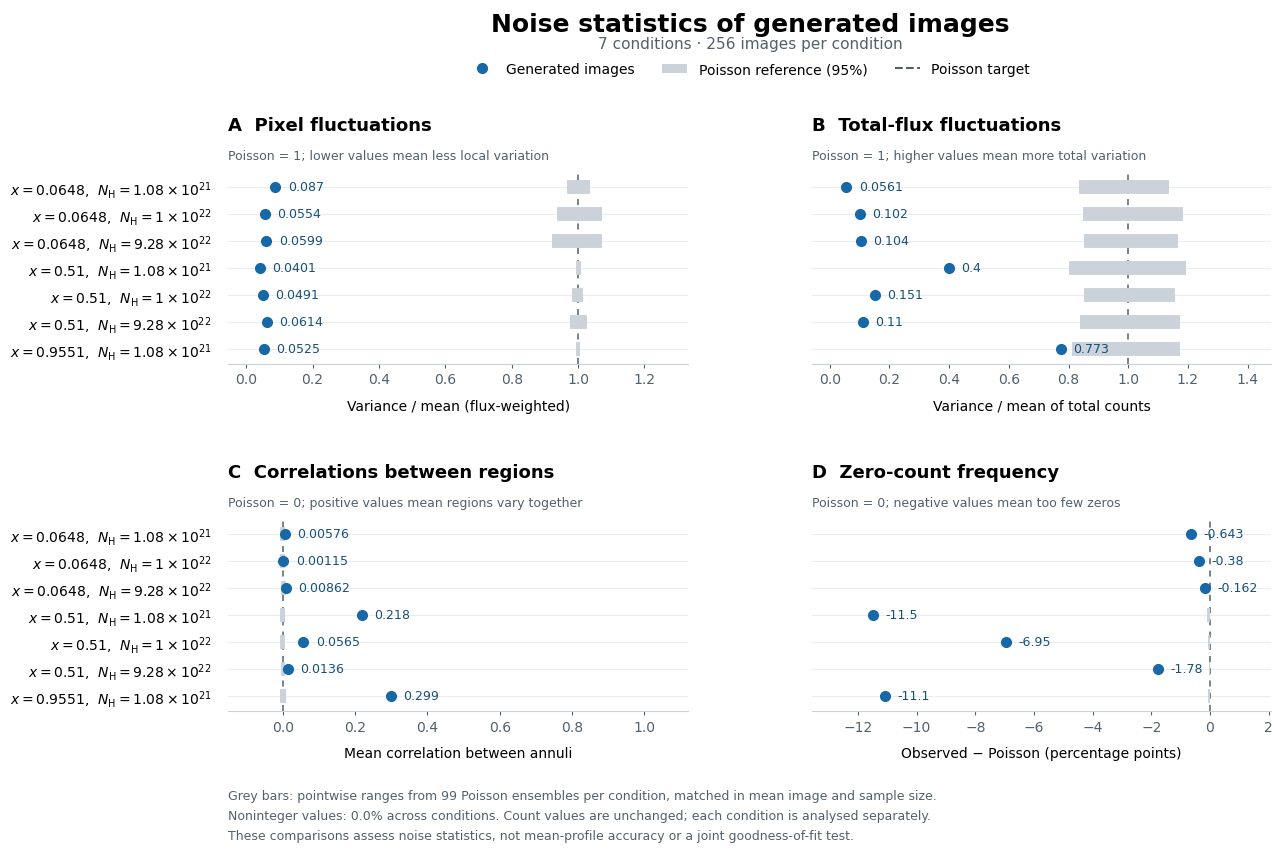

In [11]:
from utils.poisson_summary import plot_poisson_summary

fig, summary = plot_poisson_summary(
    folder="poisson_ensembles/blackout_08k",
    save_path="poisson_diagnostics_corrected_seed287/blackout_04k_summary.pdf",
)

 Summary: Poisson-deviance grid
 Statistic           : radial two-sample Poisson deviance
 Grid                : 15 x 15  (225 cells, 225 finite, 0 missing)
 Annuli per image    : 24
 Mean D_red          : 2.1647
 Std (ddof=1)        : 1.6330     SEM: 0.1089
 Median D_red        : 1.9718
 Trimmed mean (10%)  : 1.9428
 Geometric mean      : 1.8698
 IQR                 : 1.4483 - 2.4472
 Percentiles         : p90=2.9283  p95=3.7176  p99=8.5450
 Min / Max           : 0.2398 / 15.5932
 Fraction D_red <= 1.00 :   8.44%  (19/225)
 Fraction D_red <= 2.00 :  52.44%  (118/225)
 Fraction D_red <= 3.00 :  90.67%  (204/225)
------------------------------------------------------------------
 Extremes
   Lowest       0.2398  at x=0.1835, nH=3.810e+22
   Highest     15.5932  at x=0.0648, nH=1.080e+21
   ~Mean        2.1597  at x=0.6287, nH=1.810e+22
   ~Median      1.9718  at x=0.6287, nH=5.120e+22
------------------------------------------------------------------
 Colour scale        : vmin=0, vmax=

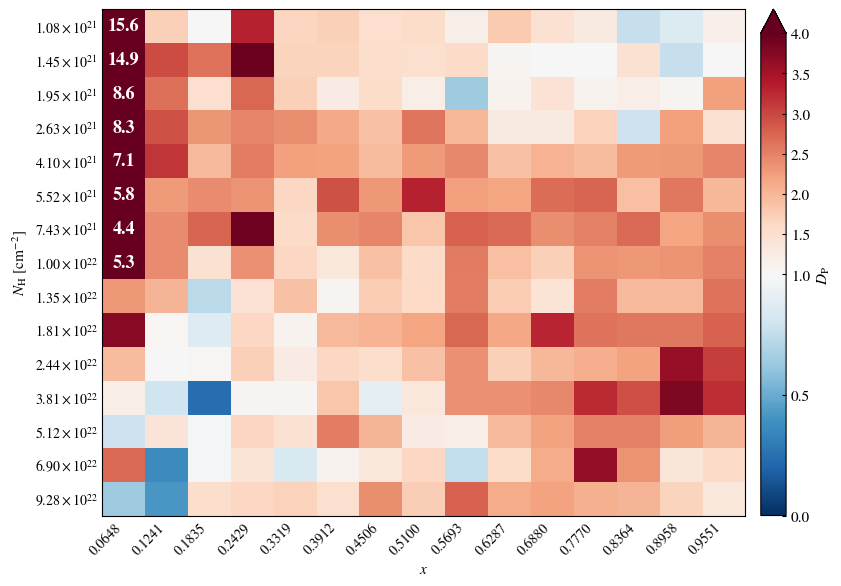

In [12]:
Error_Heatmap_B, xs, nHs = poisson_deviance_heatmap_between_npz(
    npz_model_path=f"{npz_dir}MODEL_D_12k.npz",
    npz_data_path=REFLEX_NPZ,
    n_annuli=24,
    diverging=True,
    cmap="magma",
    figsize=(9, 6),
    vmin=0.0,
    vmax=4.0,
    annotate_above=4,
    annotate_fontsize=13,
)

 Summary: Poisson-deviance grid
 Statistic           : radial two-sample Poisson deviance
 Grid                : 15 x 15  (225 cells, 225 finite, 0 missing)
 Annuli per image    : 24
 Mean D_red          : 1.4843
 Std (ddof=1)        : 2.9236     SEM: 0.1949
 Median D_red        : 1.0386
 Trimmed mean (10%)  : 1.0869
 Geometric mean      : 1.0944
 IQR                 : 0.8286 - 1.3420
 Percentiles         : p90=1.8169  p95=2.5801  p99=10.7684
 Min / Max           : 0.2507 / 31.5358
 Fraction D_red <= 1.00 :  45.33%  (102/225)
 Fraction D_red <= 2.00 :  92.44%  (208/225)
 Fraction D_red <= 3.00 :  95.56%  (215/225)
------------------------------------------------------------------
 Extremes
   Lowest       0.2507  at x=0.1241, nH=9.280e+22
   Highest     31.5358  at x=0.0648, nH=1.450e+21
   ~Mean        1.4778  at x=0.3319, nH=1.450e+21
   ~Median      1.0386  at x=0.6287, nH=1.950e+21
------------------------------------------------------------------
 Colour scale        : vmin=0, vma

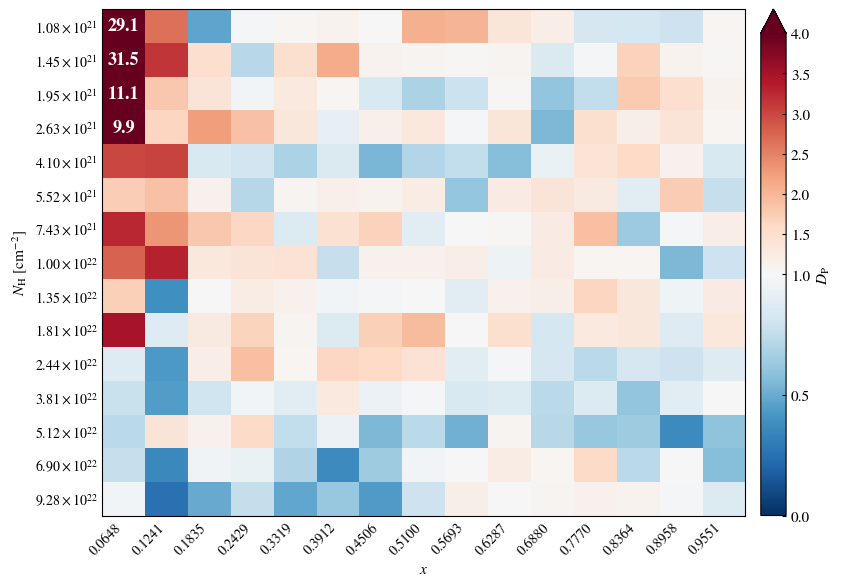

In [13]:
Error_Heatmap_B, xs, nHs = poisson_deviance_heatmap_between_npz(
    npz_model_path=f"{npz_dir}MODEL_C_15k.npz",
    npz_data_path=REFLEX_NPZ,
    n_annuli=24,
    diverging=True,
    use_N=False,
    cmap="magma",
    figsize=(9, 6),
    vmin=0.0,
    vmax=4.0,
    annotate_above=4,
    annotate_fontsize=13,
)

 Summary: error grid
 Grid                : 15 x 15  (225 cells, 225 finite, 0 missing)
 Mean                : 2.2605
 Std (ddof=1)        : 8.6372     SEM: 0.5758
 Median              : 0.9572
 Trimmed mean (10%)  : 1.0434
 Geometric mean      : 1.0548
 IQR                 : 0.7494 - 1.3194
 Percentiles         : p90=2.1481  p95=3.3394  p99=57.8877
 Min / Max           : 0.0304 / 79.9267
 Fraction <= 1.00    :  53.78%  (121/225)
 Fraction <= 2.00    :  88.89%  (200/225)
 Fraction <= 3.00    :  93.78%  (211/225)
------------------------------------------------------------------
 Extremes
   Lowest       0.0304  at x=0.0648, nH=9.280e+22
   Highest     79.9267  at x=0.0648, nH=1.450e+21
   ~Mean        2.2756  at x=0.3319, nH=1.950e+21
   ~Median      0.9572  at x=0.3912, nH=5.120e+22
------------------------------------------------------------------
 Colour scale        : vmin=0, vmax=4, extend='max'
 Clipped above vmax  : 7/225 cells (3.1%)
     x=0.0648  nH=1.450e+21   value=79.93
  

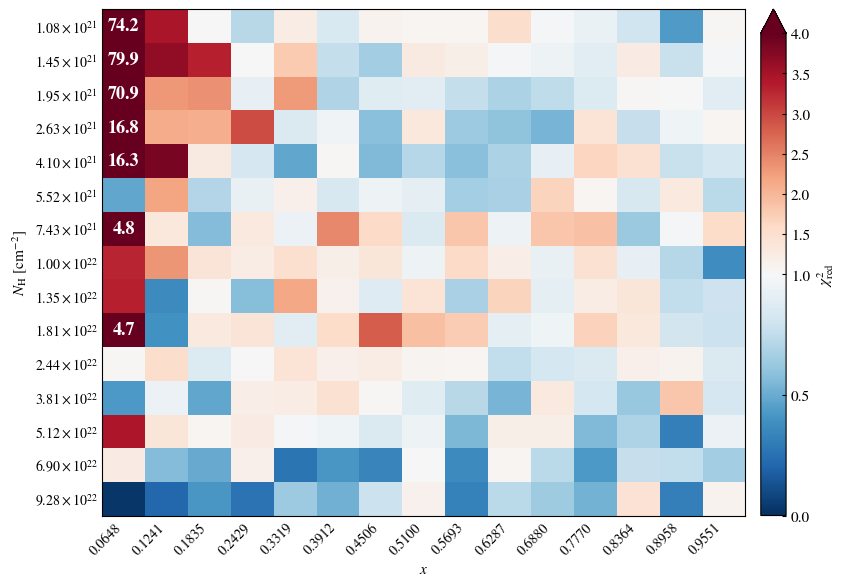

In [14]:
Error_Heatmap_B, xs, nHs = error_heatmap_between_npz(
    npz_model_path=f"{npz_dir}MODEL_C_12k.npz",
    npz_data_path=REFLEX_NPZ,
    bin_filter=10,
    n_annuli=24,
    Fano_Data=1,
    Fano_Model=1,
    use_N = True,
    diverging = True,
    cmap="magma",
    figsize=(9, 6),
    vmin=0.0,
    vmax=4.0,
    annotate_above=4,
    annotate_fontsize=13,
)

 Summary: Poisson-deviance grid
 Statistic           : radial two-sample Poisson deviance (N-normalized)
 Grid                : 15 x 15  (225 cells, 225 finite, 0 missing)
 Annuli per image    : 24
 Mean D_red          : 1.0509
 Std (ddof=1)        : 0.8459     SEM: 0.0564
 Median D_red        : 0.9001
 Trimmed mean (10%)  : 0.9559
 Geometric mean      : 0.6500
 IQR                 : 0.3231 - 1.5082
 Percentiles         : p90=2.0582  p95=2.6712  p99=3.5018
 Min / Max           : 0.0272 / 4.7912
 Fraction D_red <= 1.00 :  53.33%  (120/225)
 Fraction D_red <= 2.00 :  88.44%  (199/225)
 Fraction D_red <= 3.00 :  96.89%  (218/225)
------------------------------------------------------------------
 Extremes
   Lowest       0.0272  at x=0.9551, nH=1.080e+21
   Highest      4.7912  at x=0.0648, nH=1.350e+22
   ~Mean        1.0705  at x=0.4506, nH=1.810e+22
   ~Median      0.9001  at x=0.7770, nH=1.810e+22
------------------------------------------------------------------
 Colour scale        

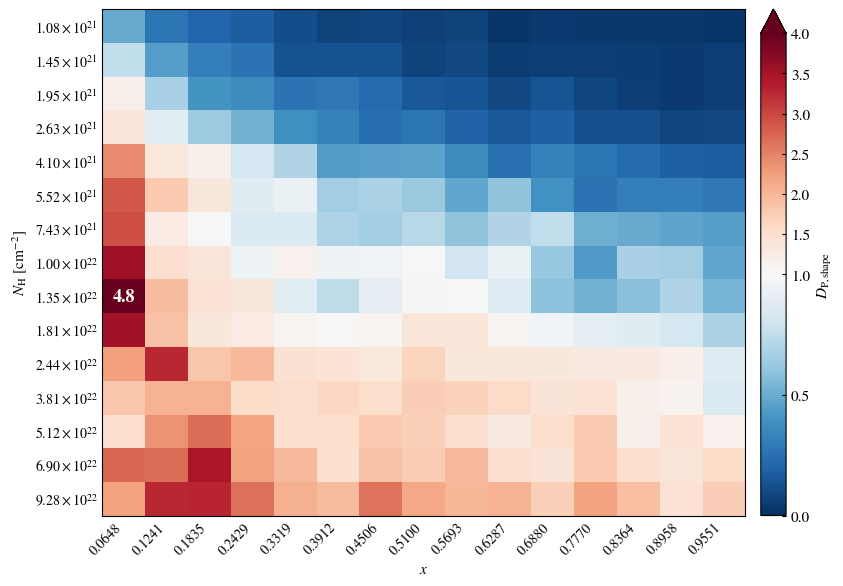

In [15]:
Error_Heatmap_B, xs, nHs = poisson_deviance_heatmap_between_npz(
    npz_model_path=TESTING_DATASET_SINGLESCAT,
    npz_data_path=REFLEX_NPZ,
    n_annuli=24,
    diverging=True,
    use_N=True,
    cmap="magma",
    figsize=(9, 6),
    vmin=0.0,
    vmax=4.0,
    annotate_above=4,
    annotate_fontsize=13,
)

In [16]:
xs

array([ 648., 1241., 1835., 2429., 3319., 3912., 4506., 5100., 5693.,
       6287., 6880., 7770., 8364., 8958., 9551.])

In [17]:
nHs

array([1.08e+21, 1.45e+21, 1.95e+21, 2.63e+21, 4.10e+21, 5.52e+21,
       7.43e+21, 1.00e+22, 1.35e+22, 1.81e+22, 2.44e+22, 3.81e+22,
       5.12e+22, 6.90e+22, 9.28e+22])

x=2429.0 -> matched x=2429.0
nH=5.12e+22 -> matched nH=5.12e+22


x_2429_0_nH_5_12e_22_poisson_deviance.png

Pairwise D_red (N-normalized Poisson deviance):
  n_annuli=24, pixel_scale=45"; fitted multiplicative normalization N per pair and direction; data counts > 0
-------------------------------------------------------
  Single Scattering vs Multiple Scattering
    D_red (Single Scattering as data) = 2.1653   dof=9   N-normalized; data counts > 0; fitted per pair, N=0.768
    D_red (Multiple Scattering as data) = 2.1856   dof=11   N-normalized; data counts > 0; fitted per pair, N=1.306
    per-annulus reduced D_red contributions:
      bin | radius[arcsec] | area[arcsec^2] | counts(Single Scattering) | counts(Multiple Scattering) | Single Scattering->Multiple Scattering | Multiple Scattering->Single Scattering
        1 |        31.157 |      8100.000 |      648.000 |       745.000 |  5.9473e-01 |  5.1099e-01
        2 |        93.471 |     40500.000 |      257.000 |       374.000 |  2.1059e-01 |  1.6283e-01
        3 |       155.784 |     56700.00

utils/error_functions.py:2278: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


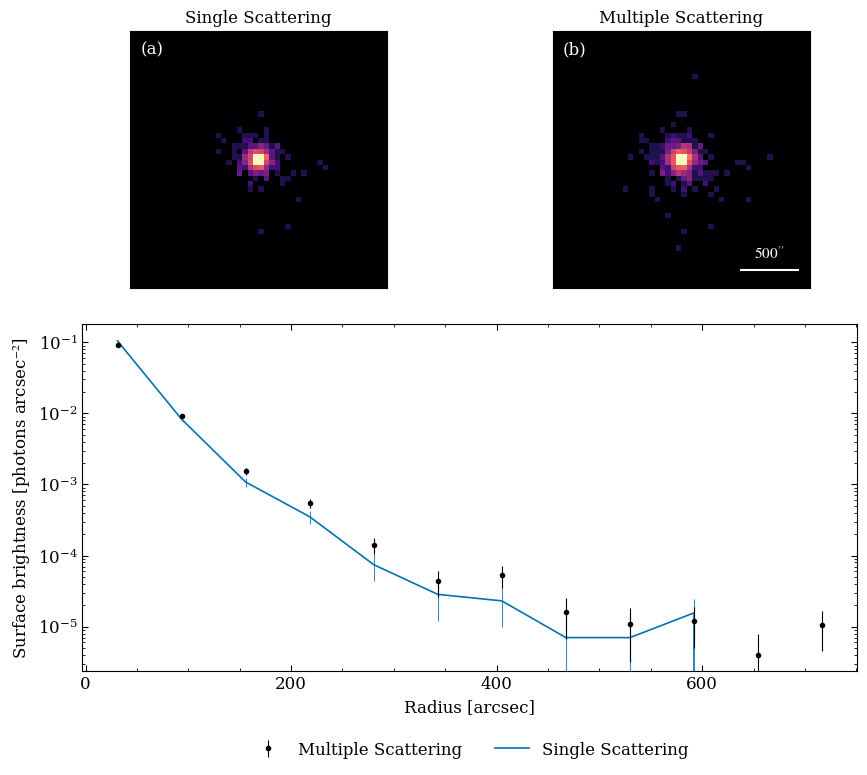

In [18]:

results = compare_npz_by_params_poisson_deviance(
    2429.0, 5.12e22,
    npz_paths=[
               TESTING_DATASET_SINGLESCAT,
               REFLEX_NPZ,
               ],
    labels=["Single Scattering", "Multiple Scattering"],
    cmaps=["magma", "magma"],
    n_annuli=24, pixel_scale_arcsec=45, bin_filter=0, use_N=True,
    a=200.0, center="geom", figsize=(10,10), font_size=12,
)

In [19]:
custom_npy_pth = f"{npy_dir}Single_Vs_All_Scat_July_10_Data/data/npy/"

save_npy_to_npz(f"{custom_npy_pth}", 
                out_path=f"{npz_dir}all_scat.npz", 
                checkpoint="",
                pattern="*.npy", 
                exclude_nH=exclude_nH, 
                exclude_x = exclude_x,k = 1.0)

Saved 40 matrices to ./npz_data_corrected_seed287/all_scat.npz with shape (48, 48) + dmin/dmax arrays.


In [20]:
custom_npy_pth = f"{npy_dir}Single_Vs_All_Scat_July_13_Data_Seed_287/singlescat_data/npy/"

save_npy_to_npz(f"{custom_npy_pth}", 
                out_path=f"{npz_dir}single_scat.npz", 
                checkpoint="",
                pattern="*.npy", 
                exclude_nH=exclude_nH, 
                exclude_x = exclude_x,k = 1.0)

Saved 40 matrices to ./npz_data_corrected_seed287/single_scat.npz with shape (48, 48) + dmin/dmax arrays.


In [21]:
custom_npy_pth = f"{npy_dir}test_absorption/npy/"

save_npy_to_npz(f"{custom_npy_pth}", 
                out_path=f"{npz_dir}test_absorption.npz", 
                checkpoint="",
                pattern="*.npy", 
                exclude_nH=exclude_nH, 
                exclude_x = exclude_x,k = 1.0)

Saved 1 matrices to ./npz_data_corrected_seed287/test_absorption.npz with shape (48, 48) + dmin/dmax arrays.


In [22]:
custom_npy_pth = f"{npy_dir}RefleX_Dataset_8_Training_1e7"

save_npy_to_npz(f"{custom_npy_pth}", 
                out_path=f"{npz_dir}reflex_training_1e7.npz", 
                checkpoint="",
                pattern="*.npy", 
                exclude_nH=exclude_nH, 
                exclude_x = exclude_x,k = 1.0)

Saved 1024 matrices to ./npz_data_corrected_seed287/reflex_training_1e7.npz with shape (48, 48) + dmin/dmax arrays.


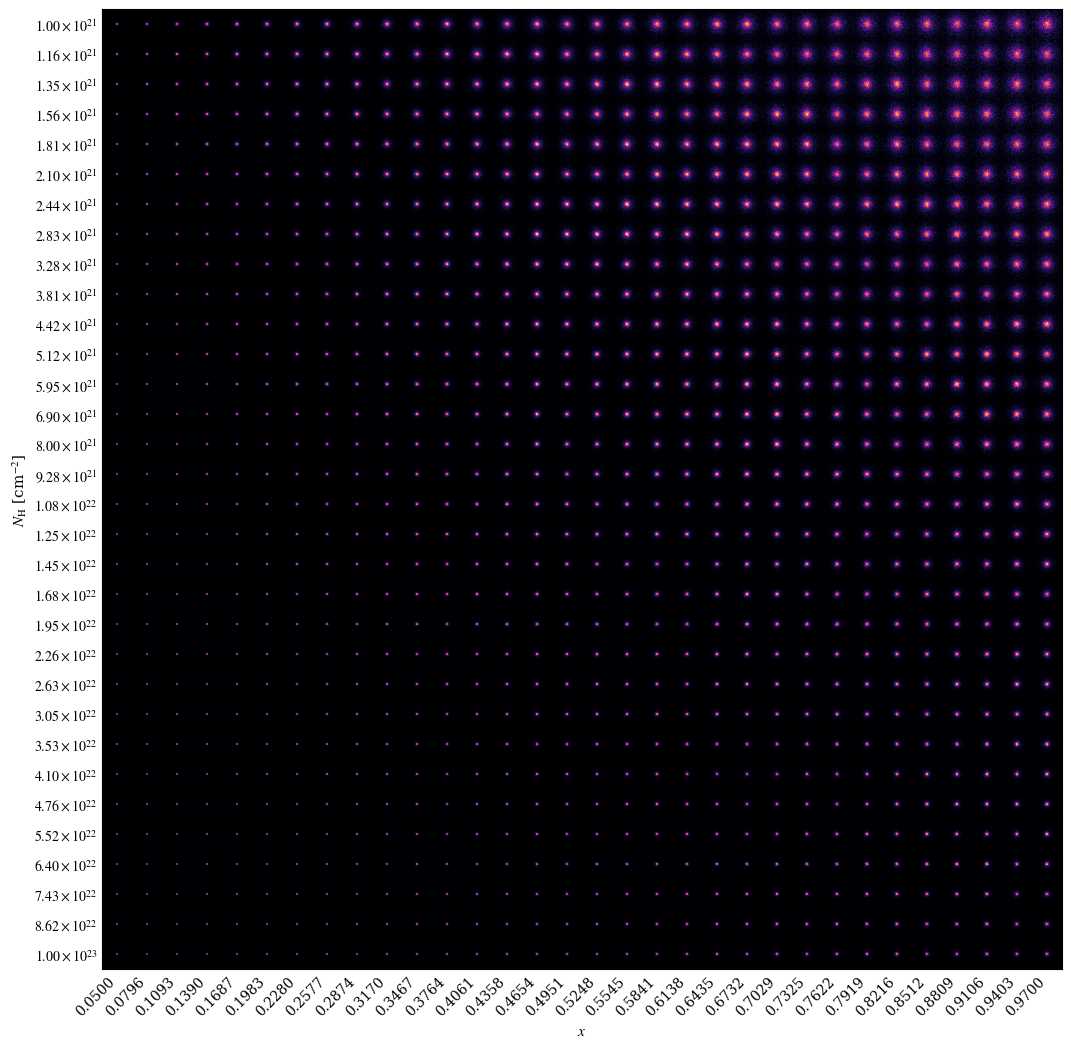

In [23]:
plot_matrix_grid(npz_path=REFLEX_NPZ_TRAINING,
                 figsize=(12,12))
plt.show()


In [24]:
custom_npy_pth = f"{npy_dir}RefleX_Dataset_8_Training_No_Absorption/"

save_npy_to_npz(f"{custom_npy_pth}", 
                out_path=f"{npz_dir}RefleX_Dataset_8_Training_No_Absorption.npz", 
                checkpoint="",
                pattern="*.npy", 
                exclude_nH=exclude_nH, 
                exclude_x = exclude_x,k = 1.0)

Saved 504 matrices to ./npz_data_corrected_seed287/RefleX_Dataset_8_Training_No_Absorption.npz with shape (48, 48) + dmin/dmax arrays.


 Summary: error grid
 Grid                : 10 x 4  (40 cells, 40 finite, 0 missing)
 Mean                : 3.4393
 Std (ddof=1)        : 2.6984     SEM: 0.4267
 Median              : 2.4155
 Trimmed mean (10%)  : 2.9387
 Geometric mean      : 2.6568
 IQR                 : 1.4690 - 4.5424
 Percentiles         : p90=5.9108  p95=9.2603  p99=11.7822
 Min / Max           : 0.7885 / 11.8965
 Fraction <= 1.00    :  10.00%  (4/40)
 Fraction <= 2.00    :  37.50%  (15/40)
 Fraction <= 3.00    :  52.50%  (21/40)
------------------------------------------------------------------
 Extremes
   Lowest       0.7885  at x=0.3467, nH=1.000e+21
   Highest     11.8965  at x=0.0500, nH=8.000e+21
   ~Mean        3.4068  at x=0.0500, nH=2.260e+22
   ~Median      2.3265  at x=0.0500, nH=1.450e+22
------------------------------------------------------------------
 Colour scale        : vmin=0, vmax=4, extend='max'
 Clipped above vmax  : 13/40 cells (32.5%)
     x=0.0500  nH=8.000e+21   value=11.90
     x=0.05

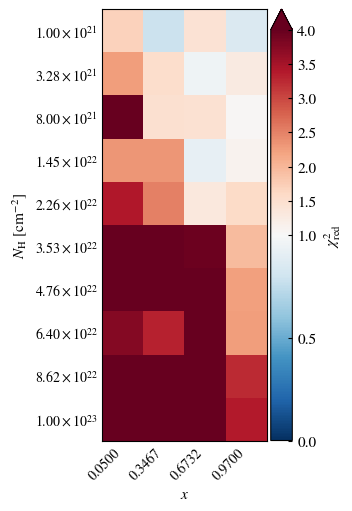

In [25]:
Error_Heatmap_C, xs, nHs = error_heatmap_between_npz(
    npz_model_path=f"{npz_dir}single_scat.npz",
    npz_data_path=f"{npz_dir}all_scat.npz",
    bin_filter=10,
    n_annuli=24,
    Fano_Data=1,
    Fano_Model=1,
    cmap="magma",
    diverging = True,
    vmin=0.0,
    vmax=4.0,
    figsize=(3.53, 5.25)
)

In [26]:
custom_npy_pth = f"{npy_dir}374_Aux_Poisson_Deviance_No_Validation_N_Fitted_Aux_12k_DDPM_multiscat_sng_sct/"

save_npy_to_npz(f"{custom_npy_pth}", 
                out_path=f"{npz_dir}all_scat_generated.npz", 
                checkpoint="",
                pattern="*.npy", 
                exclude_nH=exclude_nH, 
                exclude_x = exclude_x,k = 1.0)

Saved 40 matrices to ./npz_data_corrected_seed287/all_scat_generated.npz with shape (48, 48) + dmin/dmax arrays.


 Summary: Poisson-deviance grid
 Statistic           : radial two-sample Poisson deviance
 Grid                : 10 x 4  (40 cells, 40 finite, 0 missing)
 Annuli per image    : 24
 Mean D_red          : 0.6814
 Std (ddof=1)        : 0.6252     SEM: 0.0989
 Median D_red        : 0.5095
 Trimmed mean (10%)  : 0.5735
 Geometric mean      : 0.4742
 IQR                 : 0.2272 - 0.9155
 Percentiles         : p90=1.2396  p95=1.9711  p99=2.6980
 Min / Max           : 0.0965 / 3.0331
 Fraction D_red <= 1.00 :  77.50%  (31/40)
 Fraction D_red <= 2.00 :  95.00%  (38/40)
 Fraction D_red <= 3.00 :  97.50%  (39/40)
------------------------------------------------------------------
 Extremes
   Lowest       0.0965  at x=0.0500, nH=6.400e+22
   Highest      3.0331  at x=0.6732, nH=1.000e+21
   ~Mean        0.6928  at x=0.0500, nH=8.620e+22
   ~Median      0.5190  at x=0.3467, nH=6.400e+22
------------------------------------------------------------------
 Colour scale        : vmin=0, vmax=4, extend

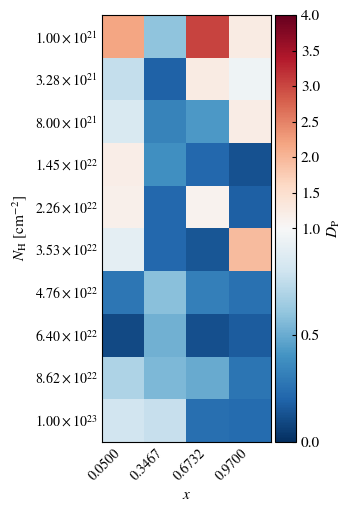

In [27]:
Error_Heatmap_C, xs, nHs = poisson_deviance_heatmap_between_npz(
    npz_model_path=f"{npz_dir}all_scat_generated.npz",
    npz_data_path=f"{npz_dir}all_scat.npz",
    n_annuli=24,
    use_N=False,
    cmap="magma",
    diverging = True,
    vmin=0.0,
    vmax=4.0,
    figsize=(3.53, 5.25)
)

x=500.0 -> matched x=500.0
nH=1.45e+22 -> matched nH=1.45e+22
x_500_0_nH_1_45e_22.png



Pairwise chi2_red (chi2):
  n_annuli=24, bin_filter=10.0, Fano Data=1.0, Fano Model=1.0, pixel_scale=45"
-------------------------------------------------------
  Dust Scattering = 1 vs Dust Scattering > 0
    chi2_red (Dust Scattering = 1 as data) = 2.3265   N_best=0.8286
    chi2_red (Dust Scattering > 0 as data) = 2.3265   N_best=1.2069
    per-annulus reduced chi2_red contributions:
      bin | radius[arcsec] | area[arcsec^2] | counts(Dust Scattering = 1) | counts(Dust Scattering > 0) | Dust Scattering = 1->Dust Scattering > 0 | Dust Scattering > 0->Dust Scattering = 1
        1 |        31.157 |      8100.000 |     2234.000 |      2648.000 |  1.9702e-01 |  1.9702e-01
        2 |        93.471 |     40500.000 |      163.000 |       237.000 |  1.7095e+00 |  1.7095e+00
        3 |       155.784 |     56700.000 |       22.000 |        34.000 |  4.1997e-01 |  4.1997e-01
        4 |       218.098 |     89100.000 |        5.000 |         1.000 |  0.0000e+00 |  0.0000e+00
        5 |    

utils/error_functions.py:2278: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


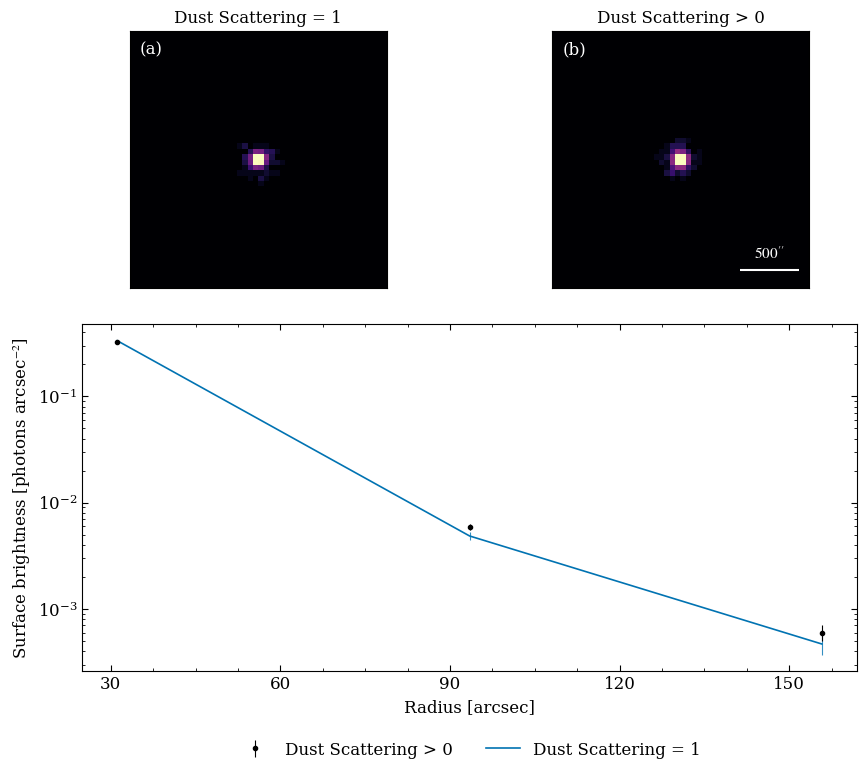

In [28]:


results = compare_npz_by_params(
    500.0, 1.45e22,
    npz_paths=[
               f"{npz_dir}single_scat.npz",
               f"{npz_dir}all_scat.npz",
               ],  # last = data
    labels=["Dust Scattering = 1","Dust Scattering > 0"],
    cmaps=["magma", "magma"],
    n_annuli=24, bin_filter=10.0, pixel_scale_arcsec=45,
    a=200.0, center="geom", figsize=(10,10), font_size=12,
)


x=3467.0 -> matched x=3467.0
nH=2.26e+22 -> matched nH=2.26e+22
x_3467_0_nH_2_26e_22.png



Pairwise chi2_red (chi2):
  n_annuli=24, bin_filter=10.0, Fano Data=1.0, Fano Model=1.0, pixel_scale=45"
-------------------------------------------------------
  Dust Scattering = 1 vs Dust Scattering > 0
    chi2_red (Dust Scattering = 1 as data) = 2.9715   N_best=0.8013
    chi2_red (Dust Scattering > 0 as data) = 2.5046   N_best=1.2539
    per-annulus reduced chi2_red contributions:
      bin | radius[arcsec] | area[arcsec^2] | counts(Dust Scattering = 1) | counts(Dust Scattering > 0) | Dust Scattering = 1->Dust Scattering > 0 | Dust Scattering > 0->Dust Scattering = 1
        1 |        31.157 |      8100.000 |      569.000 |       670.000 |  1.4748e-01 |  1.3403e-01
        2 |        93.471 |     40500.000 |      668.000 |       804.000 |  6.7990e-02 |  6.7548e-02
        3 |       155.784 |     56700.000 |      236.000 |       266.000 |  1.8335e-01 |  1.5603e-01
        4 |       218.098 |     89100.000 |       90.000 |       152.000 |  7.7007e-01 |  5.8035e-01
        5 |    

utils/error_functions.py:2278: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


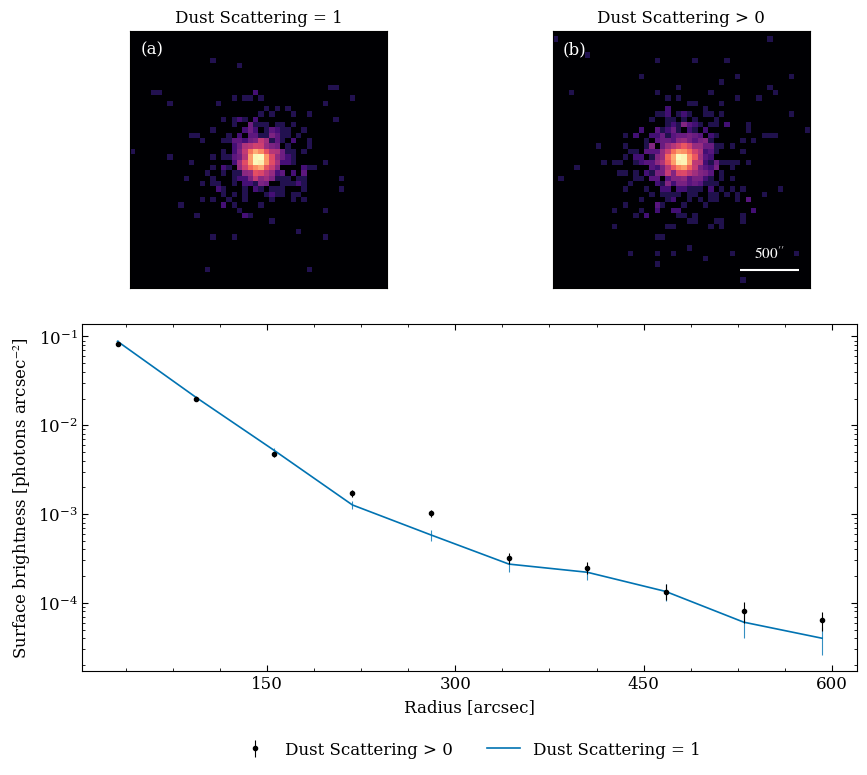

In [29]:


results = compare_npz_by_params(
    3467.0, 2.26e22,
    npz_paths=[
               f"{npz_dir}single_scat.npz",
               f"{npz_dir}all_scat.npz",
               ],  # last = data
    labels=["Dust Scattering = 1","Dust Scattering > 0"],
    cmaps=["magma", "magma"],
    n_annuli=24, bin_filter=10.0, pixel_scale_arcsec=45,
    a=200.0, center="geom", figsize=(10,10), font_size=12,
)


In [30]:
import numpy as np

with np.load("./npz_data_corrected_seed287/RefleX_Dataset_8_Training_No_Absorption.npz") as data:
    xs = np.round(data["xs"].astype(float), 6)   # decimals=6 to match the default
    nHs = np.round(data["nHs"].astype(float), 6)

x_vals = np.unique(xs)
nH_vals = np.unique(nHs)


In [31]:
nH_vals

array([1.00e+21, 1.16e+21, 1.35e+21, 1.56e+21, 1.81e+21, 2.10e+21,
       2.44e+21, 2.83e+21, 3.28e+21, 3.81e+21, 4.42e+21, 5.12e+21,
       5.95e+21, 6.90e+21, 8.00e+21, 9.28e+21, 1.08e+22, 1.25e+22,
       1.45e+22, 1.68e+22, 1.95e+22, 2.26e+22, 2.63e+22, 3.05e+22,
       3.53e+22, 4.10e+22, 4.76e+22, 5.52e+22, 6.40e+22, 7.43e+22,
       8.62e+22, 1.00e+23])

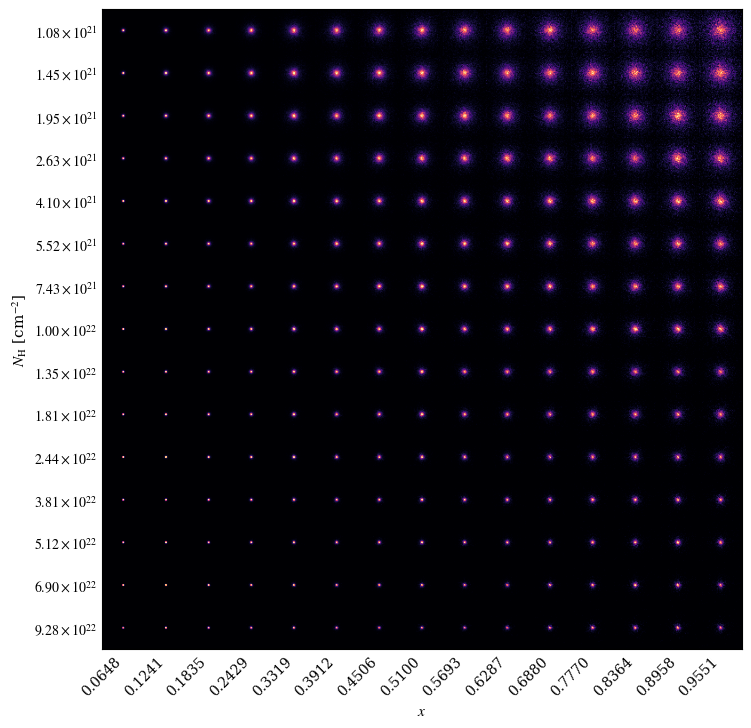

In [32]:
plot_matrix_grid(npz_path=REFLEX_NPZ,
                 figsize=(8,8))
plt.show()


 Summary: error grid
 Grid                : 15 x 15  (225 cells, 225 finite, 0 missing)
 Mean                : 3.3880
 Std (ddof=1)        : 10.6315     SEM: 0.7088
 Median              : 1.3207
 Trimmed mean (10%)  : 1.5175
 Geometric mean      : 1.5085
 IQR                 : 0.9401 - 2.0619
 Percentiles         : p90=3.5858  p95=5.6764  p99=73.9823
 Min / Max           : 0.0341 / 88.1082
 Fraction <= 1.00    :  28.89%  (65/225)
 Fraction <= 2.00    :  73.78%  (166/225)
 Fraction <= 3.00    :  85.78%  (193/225)
------------------------------------------------------------------
 Extremes
   Lowest       0.0341  at x=0.0648, nH=6.900e+22
   Highest     88.1082  at x=0.0648, nH=1.450e+21
   ~Mean        3.4030  at x=0.3912, nH=5.520e+21
   ~Median      1.3207  at x=0.6880, nH=7.430e+21
------------------------------------------------------------------
 Colour scale        : vmin=0, vmax=4, extend='max'
 Clipped above vmax  : 19/225 cells (8.4%)
     x=0.0648  nH=1.450e+21   value=88.11
 

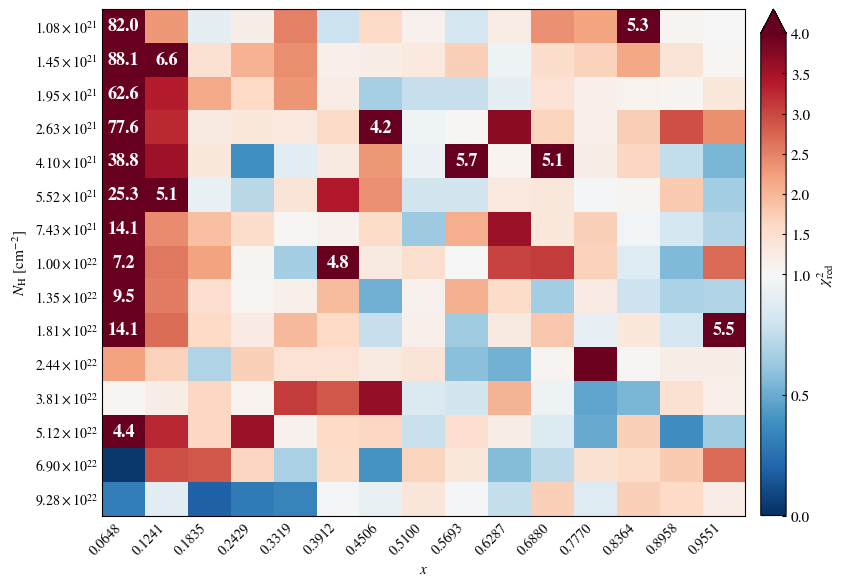

In [33]:
Error_Heatmap_B, xs, nHs = error_heatmap_between_npz(
    npz_model_path=f"{npz_dir}MODEL_C_08k.npz",
    npz_data_path=REFLEX_NPZ,
    bin_filter=10,
    n_annuli=24,
    Fano_Data=1,
    Fano_Model=1,
    use_N = False,
    diverging = True,
    cmap="magma",
    figsize=(9, 6),
    vmin=0.0,
    vmax=4.0,
    annotate_above=4,
    annotate_fontsize=13,
)

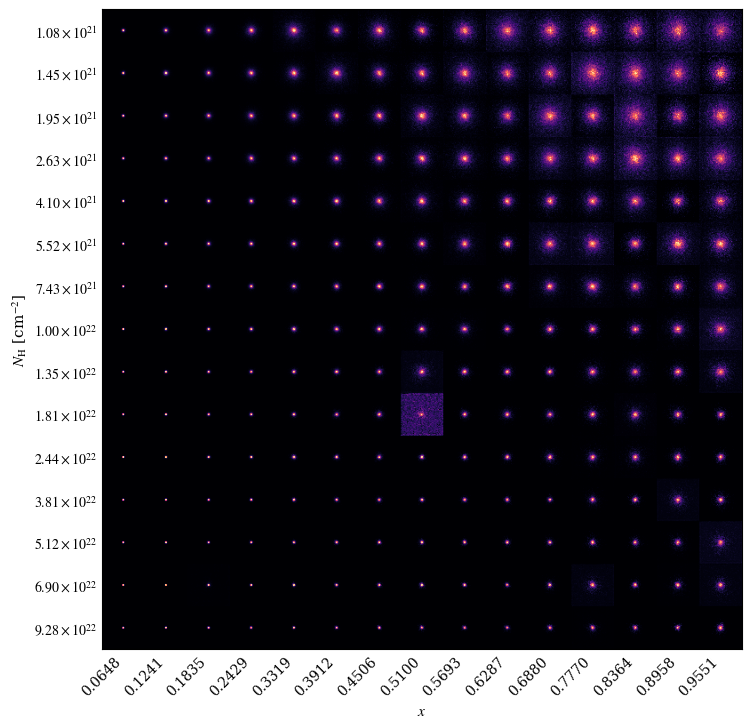

In [34]:
plot_matrix_grid(npz_path=f"{npz_dir}MODEL_C_02k.npz",
                 figsize=(8,8))
plt.show()


 Summary: Poisson-deviance grid
 Statistic           : radial two-sample Poisson deviance
 Grid                : 15 x 15  (225 cells, 225 finite, 0 missing)
 Annuli per image    : 24
 Mean D_red          : 2.0550
 Std (ddof=1)        : 2.1252     SEM: 0.1417
 Median D_red        : 1.4508
 Trimmed mean (10%)  : 1.6202
 Geometric mean      : 1.5787
 IQR                 : 1.0127 - 2.2151
 Percentiles         : p90=3.4860  p95=5.1451  p99=12.8761
 Min / Max           : 0.2304 / 16.5338
 Fraction D_red <= 1.00 :  24.44%  (55/225)
 Fraction D_red <= 2.00 :  71.11%  (160/225)
 Fraction D_red <= 3.00 :  87.11%  (196/225)
------------------------------------------------------------------
 Extremes
   Lowest       0.2304  at x=0.1835, nH=9.280e+22
   Highest     16.5338  at x=0.0648, nH=1.080e+21
   ~Mean        2.0457  at x=0.2429, nH=5.520e+21
   ~Median      1.4508  at x=0.9551, nH=2.440e+22
------------------------------------------------------------------
 Colour scale        : vmin=0, vmax

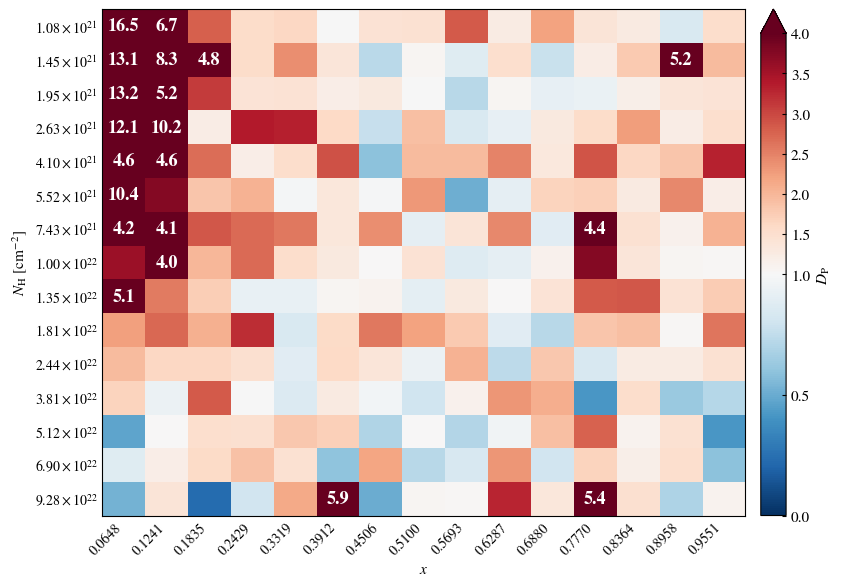

In [35]:
Error_Heatmap_B, xs, nHs = poisson_deviance_heatmap_between_npz(
    npz_model_path=f"{npz_dir}MODEL_C_09k.npz",
    npz_data_path=REFLEX_NPZ,
    n_annuli=24,
    diverging=True,
    cmap="magma",
    figsize=(9, 6),
    vmin=0.0,
    vmax=4.0,
    annotate_above=4,
    annotate_fontsize=13,
)

In [36]:
custom_npy_pth = f"{npy_dir}RefleX_Different_Seed_Grid_Increased_Camera_Center_Distance/seed_45/npy/"

save_npy_to_npz(f"{custom_npy_pth}", 
                out_path=f"{npz_dir}seed_45.npz", 
                checkpoint="",
                pattern="*.npy", 
                exclude_nH=exclude_nH, 
                exclude_x = exclude_x,k = 1.0)

Saved 16 matrices to ./npz_data_corrected_seed287/seed_45.npz with shape (50, 50) + dmin/dmax arrays.


 Summary: Poisson-deviance grid
 Statistic           : radial two-sample Poisson deviance
 Grid                : 4 x 4  (16 cells, 16 finite, 0 missing)
 Annuli per image    : 24
 Mean D_red          : 1.0317
 Std (ddof=1)        : 0.7938     SEM: 0.1984
 Median D_red        : 0.8777
 Trimmed mean (10%)  : 0.9083
 Geometric mean      : 0.8363
 IQR                 : 0.5679 - 1.0776
 Percentiles         : p90=1.6260  p95=2.1757  p99=3.3260
 Min / Max           : 0.1768 / 3.6136
 Fraction D_red <= 1.00 :  62.50%  (10/16)
 Fraction D_red <= 2.00 :  93.75%  (15/16)
 Fraction D_red <= 3.00 :  93.75%  (15/16)
------------------------------------------------------------------
 Extremes
   Lowest       0.1768  at x=0.0500, nH=1.000e+20
   Highest      3.6136  at x=0.0500, nH=1.000e+24
   ~Mean        1.0213  at x=0.9700, nH=2.150e+21
   ~Median      0.8765  at x=0.6633, nH=4.640e+22
------------------------------------------------------------------
 Colour scale        : vmin=0, vmax=4, extend=

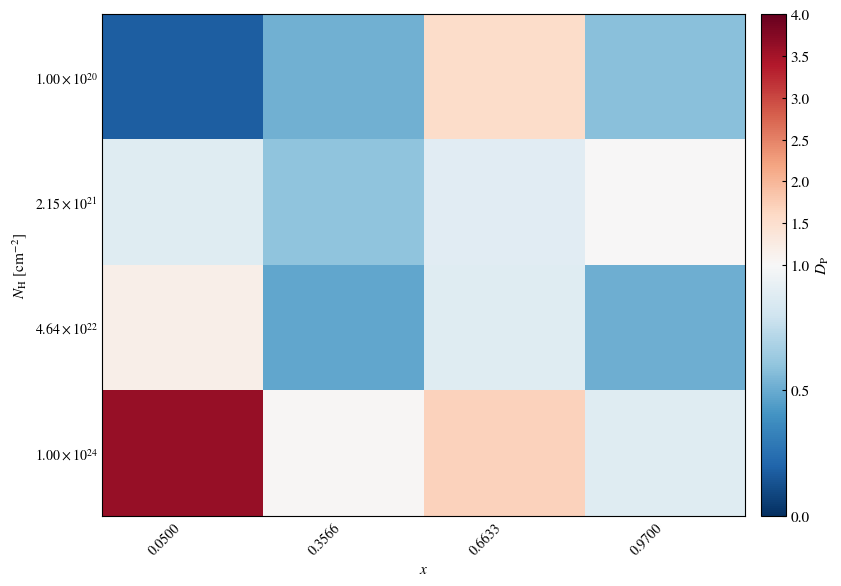

In [37]:
Error_Heatmap_B, xs, nHs = poisson_deviance_heatmap_between_npz(
    npz_model_path=f"{npz_dir}seed_334.npz",
    npz_data_path=f"{npz_dir}seed_45.npz",
    n_annuli=24,
    diverging=True,
    cmap="magma",
    figsize=(9, 6),
    vmin=0.0,
    vmax=4.0,
    annotate_above=4,
    annotate_fontsize=13,
)

In [38]:
custom_npy_pth = f"{npy_dir}RefleX_Different_Seed_Grid_Increased_Camera_Center_Distance/seed_334/npy/"

save_npy_to_npz(f"{custom_npy_pth}", 
                out_path=f"{npz_dir}seed_334.npz", 
                checkpoint="",
                pattern="*.npy", 
                exclude_nH=exclude_nH, 
                exclude_x = exclude_x,k = 1.0)

Saved 16 matrices to ./npz_data_corrected_seed287/seed_334.npz with shape (50, 50) + dmin/dmax arrays.


In [39]:
custom_npy_pth = f"{npy_dir}RefleX_Different_Seed_Grid_Increased_Camera_Center_Distance/seed_115/npy/"

save_npy_to_npz(f"{custom_npy_pth}", 
                out_path=f"{npz_dir}seed_115.npz", 
                checkpoint="",
                pattern="*.npy", 
                exclude_nH=exclude_nH, 
                exclude_x = exclude_x,k = 1.0)

Saved 16 matrices to ./npz_data_corrected_seed287/seed_115.npz with shape (50, 50) + dmin/dmax arrays.


In [40]:
custom_npy_pth = f"{npy_dir}RefleX_Different_Seed_Grid_Increased_Camera_Center_Distance/seed_284/npy/"

save_npy_to_npz(f"{custom_npy_pth}", 
                out_path=f"{npz_dir}seed_284.npz", 
                checkpoint="",
                pattern="*.npy", 
                exclude_nH=exclude_nH, 
                exclude_x = exclude_x,k = 1.0)

Saved 16 matrices to ./npz_data_corrected_seed287/seed_284.npz with shape (50, 50) + dmin/dmax arrays.


valid annuli / 24: min=2 med=16 max=24
upper-bound hits (would RuntimeError): 1187
  Rank <= 1: 0.0044
  Rank <= 2: 0.0222
  Rank <= 3: 0.0489
  Rank <= 4: 0.0533
  Rank <= 5: 0.0667
  Rank <= 6: 0.0756
  Rank <= 7: 0.0844
  Rank <= 8: 0.0978
  Rank <= 9: 0.1067
  Rank <= 10: 0.1200


valid annuli / 24: min=2 med=16 max=24
upper-bound hits (would RuntimeError): 6097
  Rank <= 1: 0.0089
  Rank <= 2: 0.0133
  Rank <= 3: 0.0400
  Rank <= 4: 0.0578
  Rank <= 5: 0.0933
  Rank <= 6: 0.1200
  Rank <= 7: 0.1467
  Rank <= 8: 0.1911
  Rank <= 9: 0.2133
  Rank <= 10: 0.2356


valid annuli / 24: min=2 med=16 max=24
upper-bound hits (would RuntimeError): 5978
  Rank <= 1: 0.0222
  Rank <= 2: 0.0311
  Rank <= 3: 0.0444
  Rank <= 4: 0.0622
  Rank <= 5: 0.1067
  Rank <= 6: 0.1378
  Rank <= 7: 0.1867
  Rank <= 8: 0.2533
  Rank <= 9: 0.2978
  Rank <= 10: 0.3289


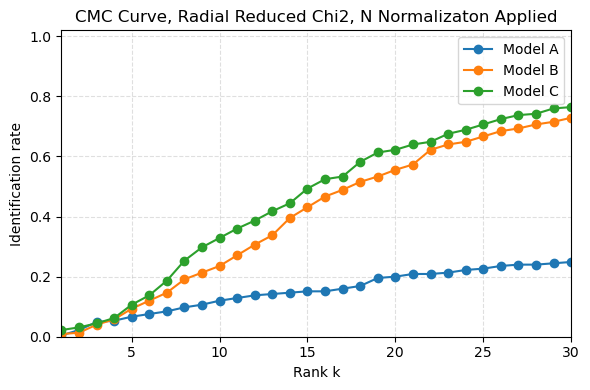

In [41]:
err_kwargs = {
    "n_annuli": 24,
    "bin_filter": 10.0,
    "use_N": True,
    "Fano_Data": 1.0,
    "Fano_Model": 1.0,
}

model_configs = [
    ("Model A", f"{npz_dir}MODEL_A_09k.npz"),
    ("Model B", f"{npz_dir}MODEL_B_09k.npz"),
    ("Model C", f"{npz_dir}MODEL_C_09k.npz"),
]

runs = {}
for label, model_npz in model_configs:
    runs[label] = compute_cmc(
        model_npz=model_npz,
        data_npz=REFLEX_NPZ,
        label=label,
        show=True,       # prints valid-annuli range + first 10 ranks
        **err_kwargs,
    )

k = 30

plt.figure(figsize=(6, 4))
for label, res in runs.items():
    plt.plot(res["ks"][:k], res["cmc"][:k], marker="o", label=label)

plt.xlabel("Rank k")
plt.ylabel("Identification rate")
plt.title("CMC Curve, Radial Reduced Chi2, N Normalizaton Applied")
plt.grid(True, linestyle="--", alpha=0.4)
plt.xlim(1, k)
plt.ylim(0, 1.02)
plt.legend()
plt.tight_layout()
plt.show()


Pairwise chi2_red (chi2):
  n_annuli=24, bin_filter=10.0, Fano Data=1.0, Fano Model=1.0, pixel_scale=45.0", use_N=True
-------------------------------------------------------
  rank1(x=0.8958, nH=9.280e+22) vs probe(x=0.3912, nH=1.350e+22)
    chi2_red (rank1(x=0.8958, nH=9.280e+22) as data) = 2.0642   N_best=0.2690
    chi2_red (probe(x=0.3912, nH=1.350e+22) as data) = 1.4854   N_best=3.7272
    per-annulus reduced chi2_red contributions:
      bin | radius[arcsec] | area[arcsec^2] | counts(rank1(x=0.8958, nH=9.280e+22)) | counts(probe(x=0.3912, nH=1.350e+22)) | rank1(x=0.8958, nH=9.280e+22)->probe(x=0.3912, nH=1.350e+22) | probe(x=0.3912, nH=1.350e+22)->rank1(x=0.8958, nH=9.280e+22)
        1 |        31.157 |      8100.000 |      136.000 |       592.288 |  3.3744e-01 |  2.0983e-01
        2 |        93.471 |     40500.000 |      263.000 |      1074.256 |  2.1941e-01 |  1.3346e-01
        3 |       155.784 |     56700.000 |      144.000 |       492.009 |  8.4201e-02 |  5.7297e-02
  

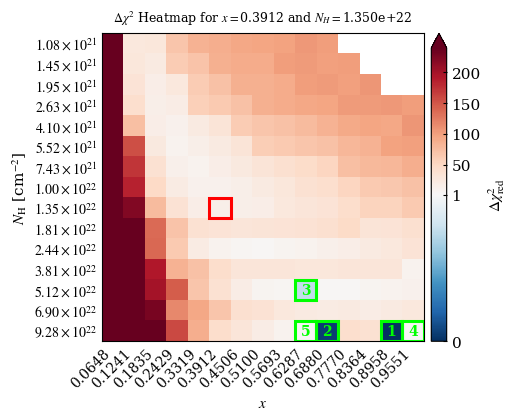

In [42]:
import numpy as np
import random 

model_npz = f"{npz_dir}MODEL_C_09k.npz"
data_npz = REFLEX_NPZ

with np.load(model_npz) as m, np.load(data_npz) as d:
    xs_m, nHs_m = m["xs"], m["nHs"]
    xs_d, nHs_d = d["xs"], d["nHs"]

res = runs["Model C"]
j = random.randrange(res["errs"].shape[1])

ax, im = plot_map(
    res,
    xs_d=xs_d, nHs_d=nHs_d,
    xs_m=xs_m, nHs_m=nHs_m,
    j=62,
    top_k=5,
    annotate=True,
    model_npz=model_npz,
    data_npz=data_npz,
    n_annuli=24, bin_filter=10.0,
    Fano_Data=1.0, Fano_Model=1.0,
    pixel_scale_arcsec=45.0,
    use_N=True,
)
plt.show()



In [43]:
nHs

array([1.00e+20, 2.15e+21, 4.64e+22, 1.00e+24])

In [44]:
xs

array([ 500., 3566., 6633., 9700.])

x=648.0 -> matched x=648.0
nH=1.08e+21 -> matched nH=1.08e+21
x_648_0_nH_1_08e_21.png

Pairwise chi2_red (chi2):
  n_annuli=24, bin_filter=0.0, Fano Data=1.0, Fano Model=1.0, pixel_scale=45"
-------------------------------------------------------
  Model D vs RefleX
    chi2_red (Model D as data) = 16.3886   N_best=1.0390
    chi2_red (RefleX as data) = 36.9714   N_best=0.9624
    per-annulus reduced chi2_red contributions:
      bin | radius[arcsec] | area[arcsec^2] | counts(Model D) | counts(RefleX) | Model D->RefleX | RefleX->Model D
        1 |        31.157 |      8100.000 |     5334.000 |      4661.000 |  2.3271e+00 |  5.8178e+00
        2 |        93.471 |     40500.000 |     3634.000 |      3634.000 |  2.6602e-01 |  6.6504e-01
        3 |       155.784 |     56700.000 |     1015.000 |      1095.000 |  6.8549e-01 |  1.7137e+00
        4 |       218.098 |     89100.000 |      225.000 |       498.000 |  1.1213e+01 |  2.8033e+01
        5 |       280.412 |    105300.000 |       54.

utils/error_functions.py:2278: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


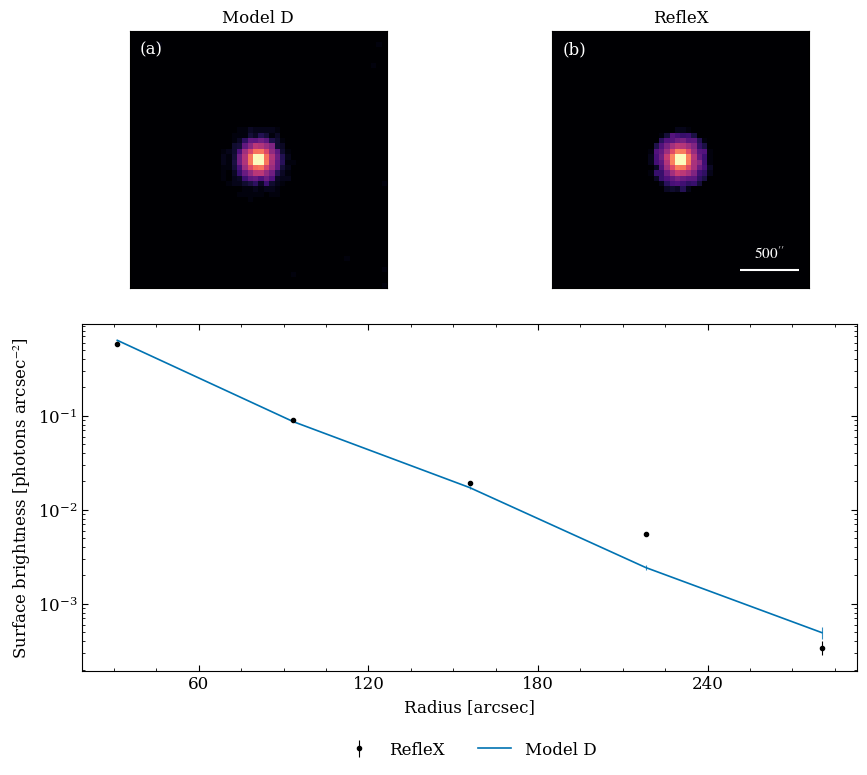

In [45]:

x = 648.0
nH = 1.08e21
results = compare_npz_by_params(
    x, nH,
    npz_paths=[
               "./npz_data_corrected_seed287/MODEL_D_08k.npz", 
               REFLEX_NPZ,
               ],
    labels=["Model D", "RefleX"],
    cmaps=["magma", "magma"],
    n_annuli=24, bin_filter=0.0, pixel_scale_arcsec=45,
    a=200.0, center="geom", figsize=(10,10), font_size=12,
)


x=648.0 -> matched x=648.0
nH=1.08e+21 -> matched nH=1.08e+21
x_648_0_nH_1_08e_21_poisson_deviance.png


utils/error_functions.py:2278: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()



Pairwise D_red (absolute Poisson deviance):
  n_annuli=24, pixel_scale=45"; no normalization; data counts > 0
-------------------------------------------------------
  Model B vs RefleX
    D_red (Model B as data) = 31.6500   dof=24   absolute; data counts > 0; no fitted normalization
    D_red (RefleX as data) = 91.4628   dof=5   absolute; data counts > 0; no fitted normalization
    per-annulus reduced D_red contributions:
      bin | radius[arcsec] | area[arcsec^2] | counts(Model B) | counts(RefleX) | Model B->RefleX | RefleX->Model B
        1 |        31.157 |      8100.000 |     5639.092 |      4661.000 |  3.8758e+00 |  1.8604e+01
        2 |        93.471 |     40500.000 |     3355.517 |      3634.000 |  4.6244e-01 |  2.2197e+00
        3 |       155.784 |     56700.000 |      855.139 |      1095.000 |  1.2324e+00 |  5.9154e+00
        4 |       218.098 |     89100.000 |       92.858 |       498.000 |  1.2714e+01 |  6.1029e+01
        5 |       280.412 |    105300.000 |        

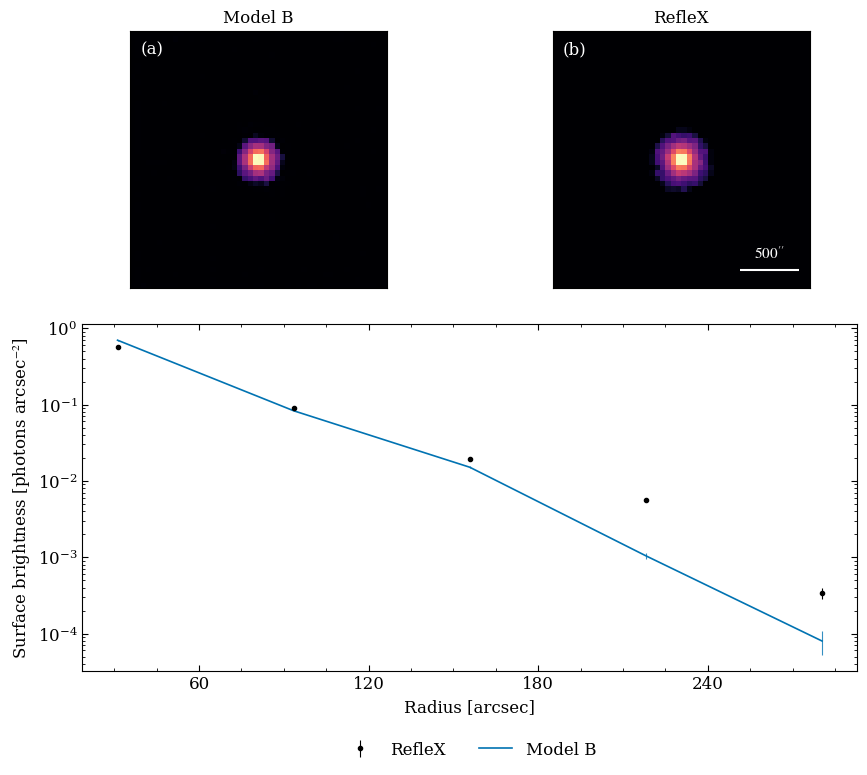

In [46]:

results = compare_npz_by_params_poisson_deviance(
    x, nH,
    npz_paths=[
               "./npz_data_corrected_seed287/MODEL_B_12k.npz", 
               REFLEX_NPZ,
               ],
    labels=["Model B", "RefleX"],
    cmaps=["magma", "magma"],
    n_annuli=24, pixel_scale_arcsec=45, use_N=False,
    a=200.0, center="geom", figsize=(10,10), font_size=12,
)

 Summary: Poisson-deviance grid
 Statistic           : radial two-sample Poisson deviance (N-normalized)
 Grid                : 10 x 4  (40 cells, 40 finite, 0 missing)
 Annuli per image    : 24
 Mean D_red          : 2.7136
 Std (ddof=1)        : 2.2837     SEM: 0.3611
 Median D_red        : 2.1058
 Trimmed mean (10%)  : 2.2024
 Geometric mean      : 2.1555
 IQR                 : 1.3973 - 3.0059
 Percentiles         : p90=5.0472  p95=7.9182  p99=10.6049
 Min / Max           : 0.7677 / 11.6277
 Fraction D_red <= 1.00 :  10.00%  (4/40)
 Fraction D_red <= 2.00 :  47.50%  (19/40)
 Fraction D_red <= 3.00 :  75.00%  (30/40)
------------------------------------------------------------------
 Extremes
   Lowest       0.7677  at x=0.3467, nH=1.000e+21
   Highest     11.6277  at x=0.0500, nH=4.760e+22
   ~Mean        2.7602  at x=0.6732, nH=6.400e+22
   ~Median      2.0891  at x=0.9700, nH=1.000e+23
------------------------------------------------------------------
 Colour scale        : vmin=0

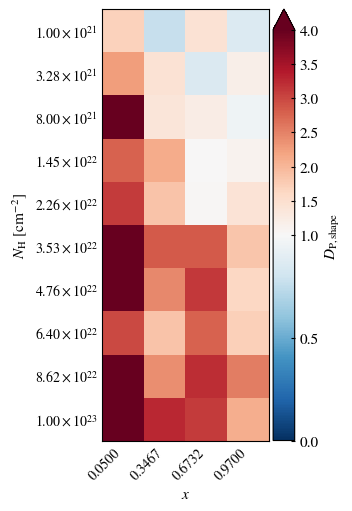

In [47]:
Error_Heatmap_C, xs, nHs = poisson_deviance_heatmap_between_npz(
    npz_model_path=f"{npz_dir}single_scat.npz",
    npz_data_path=f"{npz_dir}all_scat.npz",
    n_annuli=24,
    use_N=True,
    cmap="magma",
    diverging = True,
    vmin=0.0,
    vmax=4.0,
    figsize=(3.53, 5.25)
)

x=6732.0 -> matched x=6732.0
nH=3.53e+22 -> matched nH=3.53e+22
x_6732_0_nH_3_53e_22.png

Pairwise chi2_red (chi2):
  n_annuli=24, bin_filter=10.0, Fano Data=1.0, Fano Model=1.0, pixel_scale=45"
-------------------------------------------------------
  Single Scat vs All Scat
    chi2_red (Single Scat as data) = 4.2361   N_best=0.8016
    chi2_red (All Scat as data) = 3.9354   N_best=1.3002
    per-annulus reduced chi2_red contributions:
      bin | radius[arcsec] | area[arcsec^2] | counts(Single Scat) | counts(All Scat) | Single Scat->All Scat | All Scat->Single Scat
        1 |        31.157 |      8100.000 |      238.000 |       246.000 |  6.0047e-01 |  4.4340e-01
        2 |        93.471 |     40500.000 |      422.000 |       513.000 |  2.2048e-02 |  7.4104e-02
        3 |       155.784 |     56700.000 |      219.000 |       242.000 |  2.3858e-01 |  2.1309e-01
        4 |       218.098 |     89100.000 |      137.000 |       170.000 |  3.0508e-04 |  1.1734e-02
        5 |       280

utils/error_functions.py:2278: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


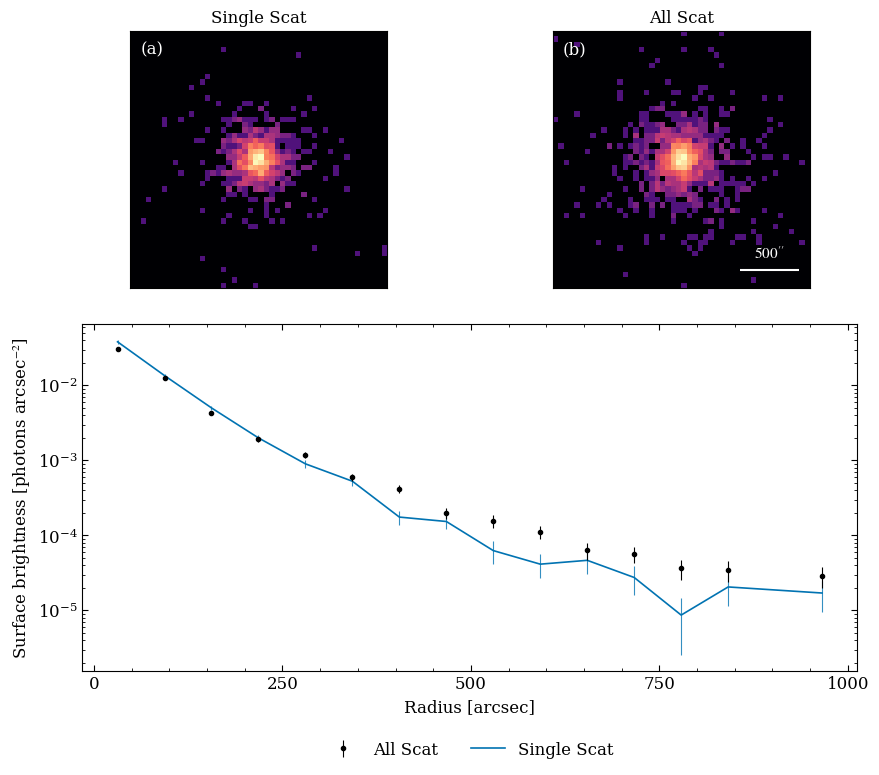

In [48]:
x = 6732.0
nH = 3.53e22
results = compare_npz_by_params(
    x, nH,
    npz_paths=[
               f"{npz_dir}single_scat.npz", 
               f"{npz_dir}all_scat.npz",
               ],
    labels=["Single Scat", "All Scat"],
    cmaps=["magma", "magma"],
    n_annuli=24, bin_filter=10.0, pixel_scale_arcsec=45,
    a=200.0, center="geom", figsize=(10,10), font_size=12,
)


 Summary: Poisson-deviance grid
 Statistic           : radial two-sample Poisson deviance
 Grid                : 15 x 15  (225 cells, 225 finite, 0 missing)
 Annuli per image    : 24
 Mean D_red          : 2.0550
 Std (ddof=1)        : 2.1252     SEM: 0.1417
 Median D_red        : 1.4508
 Trimmed mean (10%)  : 1.6202
 Geometric mean      : 1.5787
 IQR                 : 1.0127 - 2.2151
 Percentiles         : p90=3.4860  p95=5.1451  p99=12.8761
 Min / Max           : 0.2304 / 16.5338
 Fraction D_red <= 1.00 :  24.44%  (55/225)
 Fraction D_red <= 2.00 :  71.11%  (160/225)
 Fraction D_red <= 3.00 :  87.11%  (196/225)
------------------------------------------------------------------
 Extremes
   Lowest       0.2304  at x=0.1835, nH=9.280e+22
   Highest     16.5338  at x=0.0648, nH=1.080e+21
   ~Mean        2.0457  at x=0.2429, nH=5.520e+21
   ~Median      1.4508  at x=0.9551, nH=2.440e+22
------------------------------------------------------------------
 Colour scale        : vmin=0, vmax

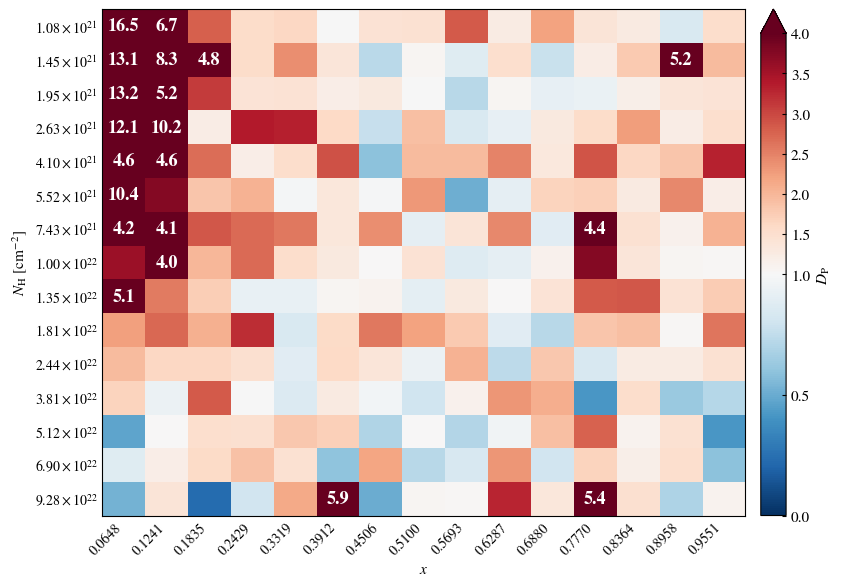

In [49]:
Error_Heatmap_B, xs, nHs = poisson_deviance_heatmap_between_npz(
    npz_model_path=f"{npz_dir}MODEL_C_09k.npz",
    npz_data_path=REFLEX_NPZ,
    n_annuli=24,
    diverging=True,
    cmap="magma",
    figsize=(9, 6),
    vmin=0.0,
    vmax=4.0,
    annotate_above=4,
    annotate_fontsize=13,
)

 Summary: Poisson-deviance grid
 Statistic           : radial two-sample Poisson deviance (N-normalized)
 Grid                : 10 x 4  (40 cells, 40 finite, 0 missing)
 Annuli per image    : 24
 Mean D_red          : 2.7136
 Std (ddof=1)        : 2.2837     SEM: 0.3611
 Median D_red        : 2.1058
 Trimmed mean (10%)  : 2.2024
 Geometric mean      : 2.1555
 IQR                 : 1.3973 - 3.0059
 Percentiles         : p90=5.0472  p95=7.9182  p99=10.6049
 Min / Max           : 0.7677 / 11.6277
 Fraction D_red <= 1.00 :  10.00%  (4/40)
 Fraction D_red <= 2.00 :  47.50%  (19/40)
 Fraction D_red <= 3.00 :  75.00%  (30/40)
------------------------------------------------------------------
 Extremes
   Lowest       0.7677  at x=0.3467, nH=1.000e+21
   Highest     11.6277  at x=0.0500, nH=4.760e+22
   ~Mean        2.7602  at x=0.6732, nH=6.400e+22
   ~Median      2.0891  at x=0.9700, nH=1.000e+23
------------------------------------------------------------------
 Colour scale        : vmin=0

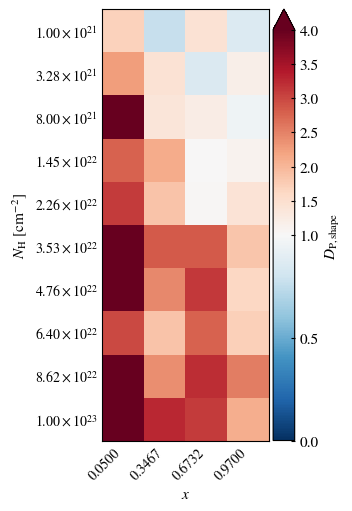

In [50]:
Error_Heatmap_C, xs, nHs = poisson_deviance_heatmap_between_npz(
    npz_model_path=f"{npz_dir}single_scat.npz",
    npz_data_path=f"{npz_dir}all_scat.npz",
    n_annuli=24,
    use_N=True,
    cmap="magma",
    diverging = True,
    vmin=0.0,
    vmax=4.0,
    figsize=(3.53, 5.25)
)

x=500.0 -> matched x=500.0
nH=3.53e+22 -> matched nH=3.53e+22
x_500_0_nH_3_53e_22_poisson_deviance.png

Pairwise D_red (N-normalized Poisson deviance):
  n_annuli=24, pixel_scale=45"; fitted multiplicative normalization N per pair and direction; data counts > 0
-------------------------------------------------------
  Single Scat vs All Scat
    D_red (Single Scat as data) = 9.0050   dof=2   N-normalized; data counts > 0; fitted per pair, N=0.7899
    D_red (All Scat as data) = 9.0050   dof=2   N-normalized; data counts > 0; fitted per pair, N=1.266
    per-annulus reduced D_red contributions:
      bin | radius[arcsec] | area[arcsec^2] | counts(Single Scat) | counts(All Scat) | Single Scat->All Scat | All Scat->Single Scat
        1 |        31.157 |      8100.000 |     1268.000 |      1556.000 |  3.3861e-01 |  3.3861e-01
        2 |        93.471 |     40500.000 |       46.000 |        93.000 |  3.5269e+00 |  3.5269e+00
        3 |       155.784 |     56700.000 |        2.000 |      

utils/error_functions.py:2278: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


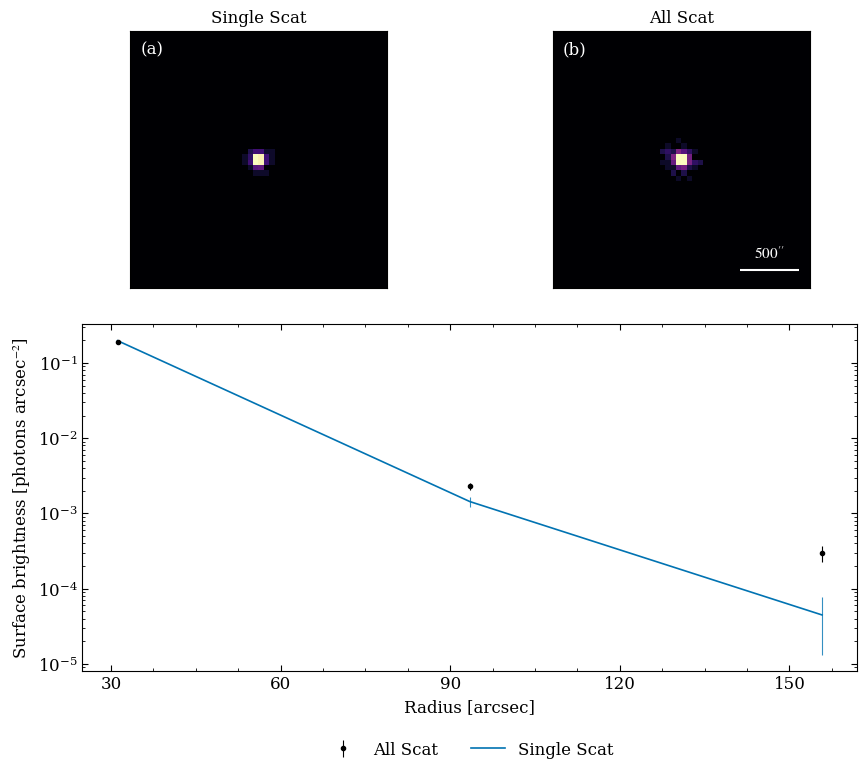

In [51]:
x = 500.0
nH = 3.53e22
results = compare_npz_by_params_poisson_deviance(
    x, nH,
    npz_paths=[
               f"{npz_dir}single_scat.npz", 
               f"{npz_dir}all_scat.npz",
               ],
    labels=["Single Scat", "All Scat"],
    cmaps=["magma", "magma"],
    n_annuli=24, pixel_scale_arcsec=45, use_N=True,
    a=200.0, center="geom", figsize=(10,10), font_size=12,
)

x=500.0 -> matched x=500.0
nH=3.53e+22 -> matched nH=3.53e+22
x_500_0_nH_3_53e_22.png

Pairwise chi2_red (chi2):
  n_annuli=24, bin_filter=10.0, Fano Data=1.0, Fano Model=1.0, pixel_scale=45"
-------------------------------------------------------
  Single Scat vs All Scat
    chi2_red (Single Scat as data) = 7.8702   N_best=0.7968
    chi2_red (All Scat as data) = 9.1369   N_best=1.2610
    per-annulus reduced chi2_red contributions:
      bin | radius[arcsec] | area[arcsec^2] | counts(Single Scat) | counts(All Scat) | Single Scat->All Scat | All Scat->Single Scat
        1 |        31.157 |      8100.000 |     1268.000 |      1556.000 |  3.5015e-01 |  2.5755e-01
        2 |        93.471 |     40500.000 |       46.000 |        93.000 |  7.5200e+00 |  3.6858e+00
        3 |       155.784 |     56700.000 |        2.000 |        17.000 |  0.0000e+00 |  5.1936e+00
        4 |       218.098 |     89100.000 |        0.000 |         0.000 |  0.0000e+00 |  0.0000e+00
        5 |       280.41

utils/error_functions.py:2278: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


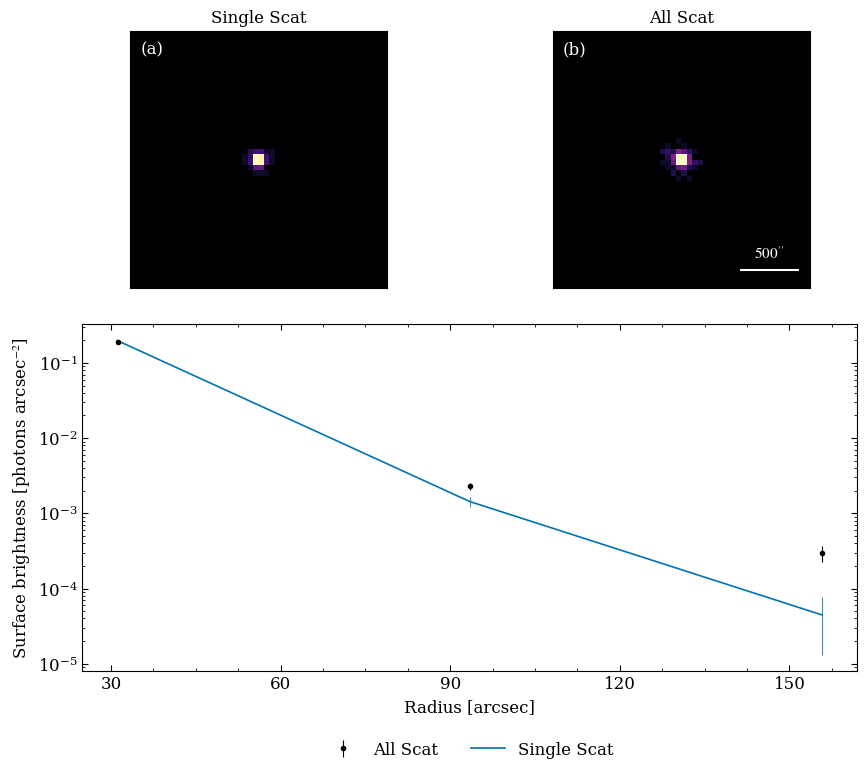

In [52]:
x = 500.0
nH = 3.53e22
results = compare_npz_by_params(
    x, nH,
    npz_paths=[
               f"{npz_dir}single_scat.npz", 
               f"{npz_dir}all_scat.npz",
               ],
    labels=["Single Scat", "All Scat"],
    cmaps=["magma", "magma"],
    n_annuli=24, bin_filter=10.0, pixel_scale_arcsec=45,
    a=200.0, center="geom", figsize=(10,10), font_size=12,
)

x=5248.0 -> matched x=5248.0
nH=1e+23 -> matched nH=1e+23
x_5248_0_nH_1e_23.png

Pairwise chi2_red (chi2):
  n_annuli=24, bin_filter=10.0, Fano Data=1.0, Fano Model=1.0, pixel_scale=45"
-------------------------------------------------------


utils/error_functions.py:2291: SyntaxWarning: invalid escape sequence '\l'
  """


RuntimeError: The fitted normalization reached the optimization upper bound (1595.69). Increase the bound or inspect the data/model scaling.

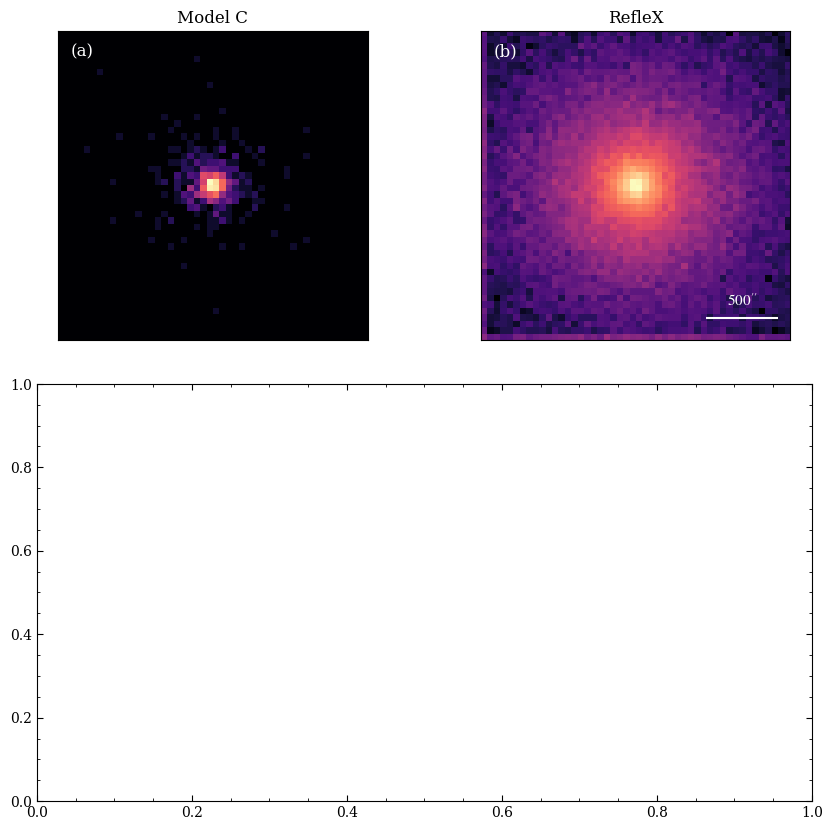

In [53]:

x = 5248.0
nH = 1.00e23
results = compare_npz_by_params(
    x, nH,
    npz_paths=[
               REFLEX_NPZ_TRAINING,
               "./npz_data_corrected_seed287/test_absorption.npz",
               ],
    labels=["Model C", "RefleX"],
    cmaps=["magma", "magma"],
    n_annuli=24, bin_filter=10.0, pixel_scale_arcsec=45,
    a=200.0, center="geom", figsize=(10,10), font_size=12,
)


x=5248.0 -> matched x=5248.0
nH=1e+21 -> matched nH=1e+21
x=5248.0 -> matched x=5248.0
nH=1e+23 -> matched nH=1e+23
REFLEX_TRAINING_x5248_0_nH1e_21_test_absorption_x5248_0_nH1e_23.png

Pairwise chi2_red (chi2):
  n_annuli=24, bin_filter=10.0, Fano Data=1.0, Fano Model=1.0, pixel_scale=45"
-------------------------------------------------------
  Low nH 1e21 vs High nH 1e23
    chi2_red (Low nH 1e21 as data) = 91.6634   N_best=0.0529
    chi2_red (High nH 1e23 as data) = 93.0959   N_best=19.2508
    per-annulus reduced chi2_red contributions:
      bin | radius[arcsec] | area[arcsec^2] | counts(Low nH 1e21) | counts(High nH 1e23) | Low nH 1e21->High nH 1e23 | High nH 1e23->Low nH 1e21
        1 |        31.157 |      8100.000 |      212.000 |      2408.000 |  1.4859e+00 |  1.5032e+00
        2 |        93.471 |     40500.000 |      773.000 |      7211.000 |  8.7778e+00 |  8.7091e+00
        3 |       155.784 |     56700.000 |      786.000 |      6725.000 |  1.0447e+01 |  1.0309e+01
    

utils/error_functions.py:2278: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


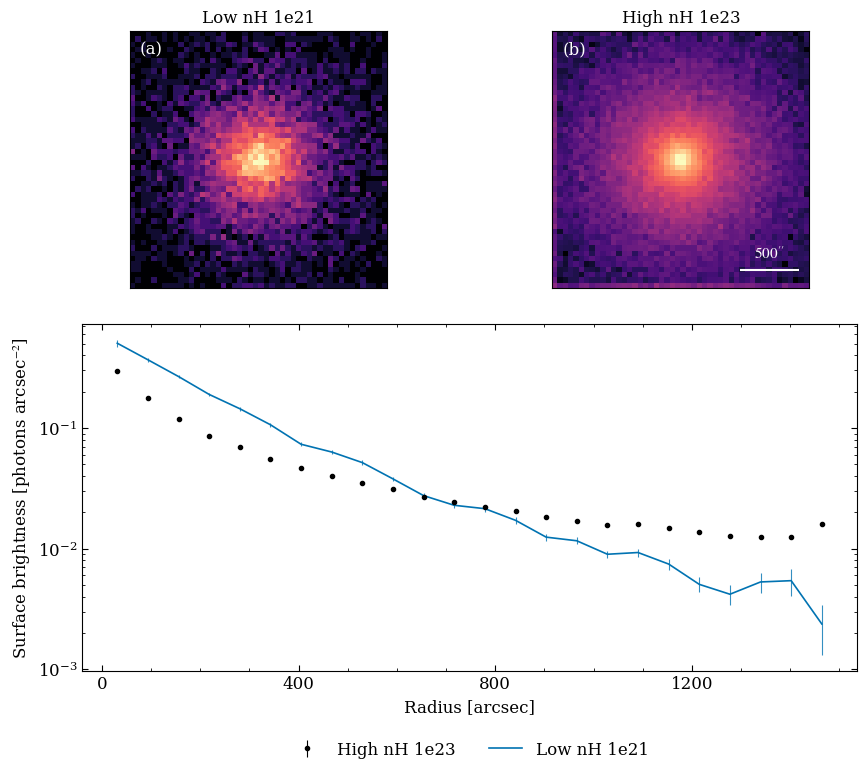

{(0, 1): (91.66342444127378, 93.09592127582137)}

In [54]:
compare_npz_by_param_pairs(
    npz_paths=[REFLEX_NPZ_TRAINING, "./npz_data_corrected_seed287/test_absorption.npz"],
    xs=[5248.0, 5248.0],
    nHs=[1.00e21, 1.00e23],
    labels=["Low nH 1e21", "High nH 1e23"],
    cmaps=["magma", "magma"],
    n_annuli=24, bin_filter=10.0, pixel_scale_arcsec=45,
    a=200.0, center="geom", figsize=(10, 10), font_size=12,
)


x=2429.0 -> matched x=2429.0
nH=2.63e+21 -> matched nH=2.63e+21


x_2429_0_nH_2_63e_21_poisson_deviance.png

Pairwise D_red (absolute Poisson deviance):
  n_annuli=24, pixel_scale=45"; no normalization; data counts > 0
-------------------------------------------------------
  Model A vs Model C
    D_red (Model A as data) = 19.2352   dof=24   absolute; data counts > 0; no fitted normalization
    D_red (Model C as data) = 19.2352   dof=24   absolute; data counts > 0; no fitted normalization
    per-annulus reduced D_red contributions:
      bin | radius[arcsec] | area[arcsec^2] | counts(Model A) | counts(Model C) | Model A->Model C | Model C->Model A
        1 |        31.157 |      8100.000 |     1108.082 |      1058.133 |  4.7993e-02 |  4.7993e-02
        2 |        93.471 |     40500.000 |     2203.576 |      2120.295 |  6.6839e-02 |  6.6839e-02
        3 |       155.784 |     56700.000 |     1305.093 |      1233.776 |  8.3482e-02 |  8.3482e-02
        4 |       218.098 |     89100.000 |     1030.608 |       983.742 |  4.5437e-02 |  4.5437e-02
   

utils/error_functions.py:2278: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


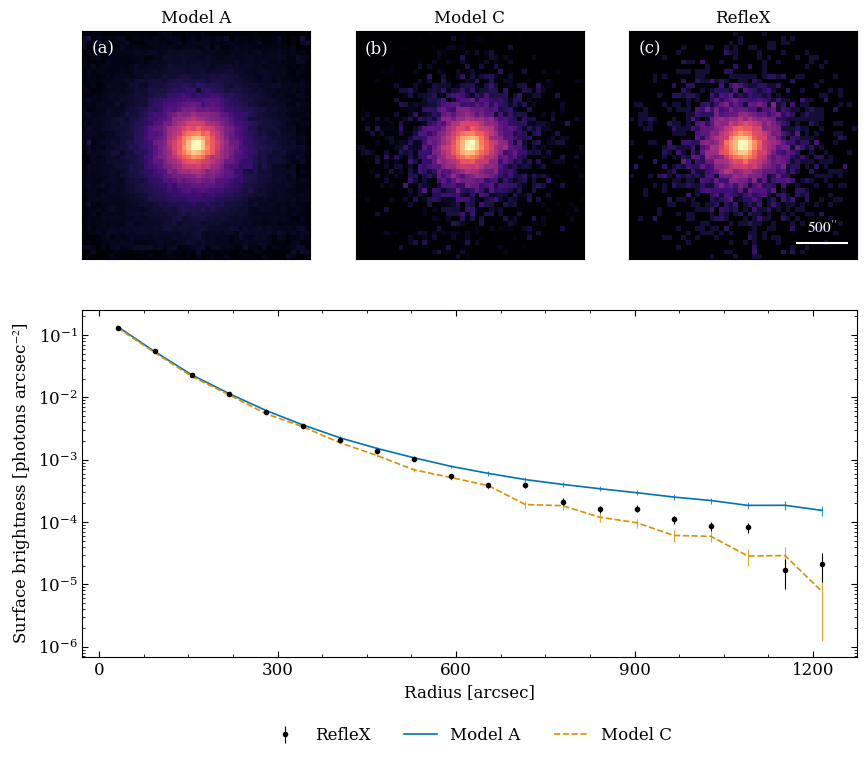

In [55]:

x = 2429.0
nH = 2.63e21
results = compare_npz_by_params_poisson_deviance(
    x, nH,
    npz_paths=[
               "./npz_data_corrected_seed287/MODEL_A_20k.npz",
               "./npz_data_corrected_seed287/MODEL_C_12k.npz", 
               REFLEX_NPZ,
               ],
    labels=["Model A", "Model C","RefleX"],
    cmaps=["magma", "magma", "magma"],
    n_annuli=24, pixel_scale_arcsec=45, use_N=False,
    a=200.0, center="geom", figsize=(10,10), font_size=12,
)


In [56]:
xs

array([ 500., 3467., 6732., 9700.])

In [57]:
nHs

array([1.00e+21, 3.28e+21, 8.00e+21, 1.45e+22, 2.26e+22, 3.53e+22,
       4.76e+22, 6.40e+22, 8.62e+22, 1.00e+23])

x=3912.0 -> matched x=3912.0
nH=1e+22 -> matched nH=1e+22
x_3912_0_nH_1e_22_poisson_deviance.png

Pairwise D_red (absolute Poisson deviance):
  n_annuli=24, pixel_scale=45"; no normalization; bin_filter=10
-------------------------------------------------------
  Model C vs RefleX
    D_red (Model C as data) = 1.3238   dof=17   absolute; bin_filter=10; no fitted normalization
    D_red (RefleX as data) = 1.3238   dof=17   absolute; bin_filter=10; no fitted normalization
    per-annulus reduced D_red contributions:
      bin | radius[arcsec] | area[arcsec^2] | counts(Model C) | counts(RefleX) | Model C->RefleX | RefleX->Model C
        1 |        31.157 |      8100.000 |      545.103 |       566.000 |  2.3120e-02 |  2.3120e-02
        2 |        93.471 |     40500.000 |     1119.677 |      1156.000 |  3.4105e-02 |  3.4105e-02
        3 |       155.784 |     56700.000 |      591.098 |       591.000 |  4.7535e-07 |  4.7535e-07
        4 |       218.098 |     89100.000 |      409.243 |    

utils/error_functions.py:2278: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


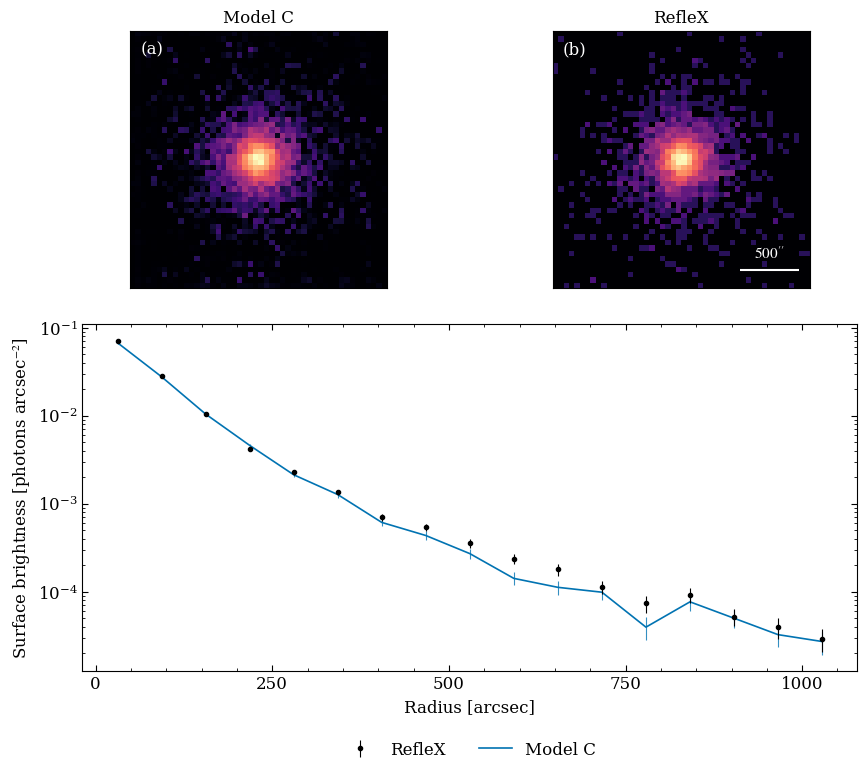

In [58]:

x = 2429.0
nH = 2.63e21

x = 3912.0
nH = 1.00e22
results = compare_npz_by_params_poisson_deviance(
    x, nH,
    npz_paths=[
               "./npz_data_corrected_seed287/MODEL_C_12k.npz", 
               REFLEX_NPZ,
               ],
    labels=["Model C","RefleX"],
    cmaps=["magma", "magma"],
    n_annuli=24, pixel_scale_arcsec=45, bin_filter = 10, use_N=False,
    a=200.0, center="geom", figsize=(10,10), font_size=12,
)


 Summary: error grid
 Grid                : 10 x 4  (40 cells, 40 finite, 0 missing)
 Mean                : 3.4393
 Std (ddof=1)        : 2.6984     SEM: 0.4267
 Median              : 2.4155
 Trimmed mean (10%)  : 2.9387
 Geometric mean      : 2.6568
 IQR                 : 1.4690 - 4.5424
 Percentiles         : p90=5.9108  p95=9.2603  p99=11.7822
 Min / Max           : 0.7885 / 11.8965
 Fraction <= 1.00    :  10.00%  (4/40)
 Fraction <= 2.00    :  37.50%  (15/40)
 Fraction <= 3.00    :  52.50%  (21/40)
------------------------------------------------------------------
 Extremes
   Lowest       0.7885  at x=0.3467, nH=1.000e+21
   Highest     11.8965  at x=0.0500, nH=8.000e+21
   ~Mean        3.4068  at x=0.0500, nH=2.260e+22
   ~Median      2.3265  at x=0.0500, nH=1.450e+22
------------------------------------------------------------------
 Colour scale        : vmin=0, vmax=4, extend='max'
 Clipped above vmax  : 13/40 cells (32.5%)
     x=0.0500  nH=8.000e+21   value=11.90
     x=0.05

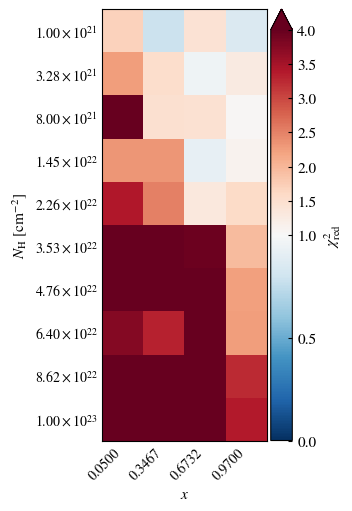

In [59]:
Error_Heatmap_C, xs, nHs = error_heatmap_between_npz(
    npz_model_path=f"{npz_dir}single_scat.npz",
    npz_data_path=f"{npz_dir}all_scat.npz",
    bin_filter=10,
    n_annuli=24,
    Fano_Data=1,
    Fano_Model=1,
    cmap="magma",
    diverging = True,
    vmin=0.0,
    vmax=4.0,
    figsize=(3.53, 5.25)
)

In [60]:
xs

array([ 500., 3467., 6732., 9700.])

In [61]:
nHs

array([1.00e+21, 3.28e+21, 8.00e+21, 1.45e+22, 2.26e+22, 3.53e+22,
       4.76e+22, 6.40e+22, 8.62e+22, 1.00e+23])

x=3467.0 -> matched x=3467.0
nH=6.4e+22 -> matched nH=6.4e+22
x_3467_0_nH_6_4e_22_poisson_deviance.png

Pairwise D_red (N-normalized Poisson deviance):
  n_annuli=24, pixel_scale=45"; fitted multiplicative normalization N per pair and direction; bin_filter=10
-------------------------------------------------------
  Single Scattering vs Multiple Scattering
    D_red (Single Scattering as data) = 3.3636   dof=5   N-normalized; bin_filter=10; fitted per pair, N=0.7466
    D_red (Multiple Scattering as data) = 3.2639   dof=6   N-normalized; bin_filter=10; fitted per pair, N=1.351
    per-annulus reduced D_red contributions:
      bin | radius[arcsec] | area[arcsec^2] | counts(Single Scattering) | counts(Multiple Scattering) | Single Scattering->Multiple Scattering | Multiple Scattering->Single Scattering
        1 |        31.157 |      8100.000 |      441.000 |       499.000 |  1.3251e+00 |  1.2186e+00
        2 |        93.471 |     40500.000 |      263.000 |       391.000 |  3.4475e-01

utils/error_functions.py:2278: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


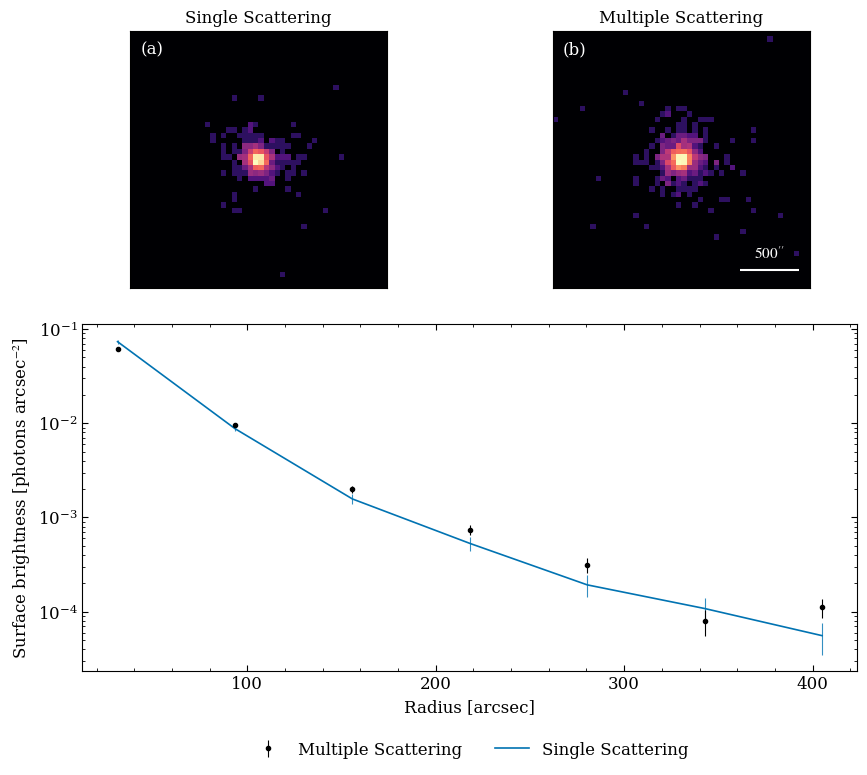

In [62]:

x = 2429.0
nH = 2.63e21

x = 3467.0
nH = 6.4e22
results = compare_npz_by_params_poisson_deviance(
    x, nH,
    npz_paths=[
               f"{npz_dir}single_scat.npz",
               f"{npz_dir}all_scat.npz",
               ],
    labels=["Single Scattering","Multiple Scattering"],
    cmaps=["magma", "magma"],
    n_annuli=24, pixel_scale_arcsec=45, bin_filter = 10, use_N=True,
    a=200.0, center="geom", figsize=(10,10), font_size=12,
)


 Summary: Poisson-deviance grid
 Statistic           : radial two-sample Poisson deviance
 Grid                : 15 x 15  (225 cells, 225 finite, 0 missing)
 Annuli per image    : 24
 Mean D_red          : 2.2493
 Std (ddof=1)        : 7.3879     SEM: 0.4925
 Median D_red        : 1.0760
 Trimmed mean (10%)  : 1.1706
 Geometric mean      : 1.2223
 IQR                 : 0.8326 - 1.5464
 Percentiles         : p90=2.3193  p95=3.6752  p99=50.9810
 Min / Max           : 0.2550 / 68.3960
 Fraction D_red <= 1.00 :  42.67%  (96/225)
 Fraction D_red <= 2.00 :  87.11%  (196/225)
 Fraction D_red <= 3.00 :  92.44%  (208/225)
------------------------------------------------------------------
 Extremes
   Lowest       0.2550  at x=0.0648, nH=9.280e+22
   Highest     68.3960  at x=0.0648, nH=1.450e+21
   ~Mean        2.2929  at x=0.6880, nH=5.520e+21
   ~Median      1.0760  at x=0.1241, nH=2.440e+22
------------------------------------------------------------------
 Colour scale        : vmin=0, vmax

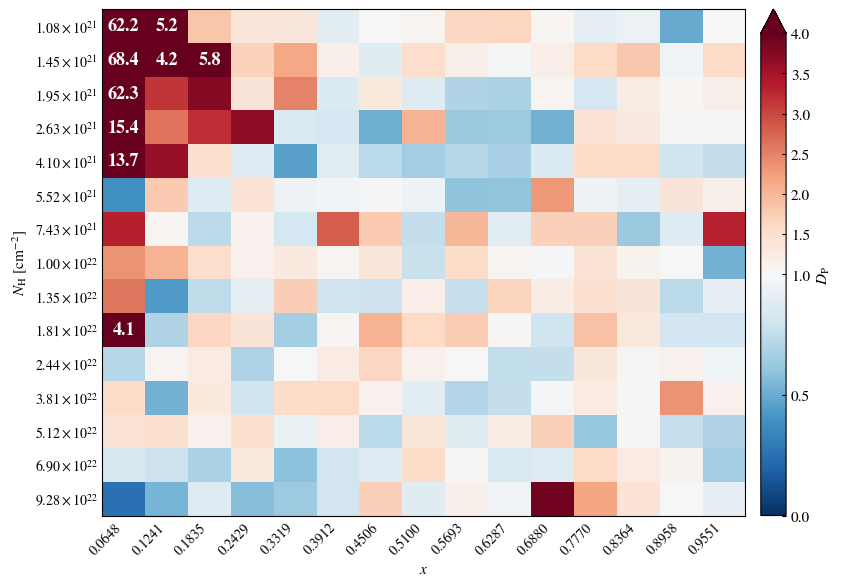

In [63]:
Error_Heatmap_B, xs, nHs = poisson_deviance_heatmap_between_npz(
    npz_model_path=f"{npz_dir}MODEL_C_12k.npz",
    npz_data_path=REFLEX_NPZ,
    n_annuli=24,
    diverging=True,
    cmap="magma",
    figsize=(9, 6),
    vmin=0.0,
    vmax=4.0,
    annotate_above=4,
    annotate_fontsize=13,
)

## Interpolation baseline
Bilinear interpolation of the **training** images (seed 42, 32x32 grid) in $(x, \log_{10} N_H)$ to the 225 test conditions, evaluated against the same independent seed-287 RefleX test set (`REFLEX_NPZ`) as Model C at 15k. Test points are cell midpoints, so each interpolated image is a weighted average of the 4 surrounding training images.

In [64]:
import numpy as np
from scipy.interpolate import RegularGridInterpolator

# --- bilinear interpolation of the training images in (x, log10 N_H) ---
with np.load(REFLEX_NPZ_TRAINING) as tr:
    tr_x, tr_nh, tr_m = tr["xs"].astype(float), tr["nHs"].astype(float), tr["mats"].astype(float)
with np.load(REFLEX_NPZ) as te:
    te_x, te_nh = te["xs"].astype(float), te["nHs"].astype(float)

gx = np.unique(tr_x); gl = np.unique(np.log10(tr_nh))
cube = np.zeros((len(gx), len(gl), 48, 48))
for x, nh, m in zip(tr_x, tr_nh, tr_m):
    cube[np.searchsorted(gx, x), np.searchsorted(gl, np.log10(nh))] = m
assert len(gx) * len(gl) == len(tr_x)

interp = RegularGridInterpolator((gx, gl), cube, method="linear")
interp_mats = interp(np.column_stack([te_x, np.log10(te_nh)])).astype(np.float32)

INTERP_NPZ = f"{npz_dir}INTERP_BILINEAR_00k.npz"
np.savez(INTERP_NPZ, xs=te_x, nHs=te_nh, mats=interp_mats,
         dmin=interp_mats.min(axis=(1, 2)), dmax=interp_mats.max(axis=(1, 2)), H=48, W=48)
print("Saved", interp_mats.shape, "interpolated images to", INTERP_NPZ)


Saved (225, 48, 48) interpolated images to ./npz_data_corrected_seed287/INTERP_BILINEAR_00k.npz


 Summary: Poisson-deviance grid
 Statistic           : radial two-sample Poisson deviance
 Grid                : 15 x 15  (225 cells, 225 finite, 0 missing)
 Annuli per image    : 24
 Mean D_red          : 1.0928
 Std (ddof=1)        : 1.9624     SEM: 0.1308
 Median D_red        : 0.7462
 Trimmed mean (10%)  : 0.7915
 Geometric mean      : 0.8213
 IQR                 : 0.6219 - 0.9583
 Percentiles         : p90=1.2851  p95=1.9465  p99=9.0799
 Min / Max           : 0.1751 / 22.8083
 Fraction D_red <= 1.00 :  79.56%  (179/225)
 Fraction D_red <= 2.00 :  95.11%  (214/225)
 Fraction D_red <= 3.00 :  97.33%  (219/225)
------------------------------------------------------------------
 Extremes
   Lowest       0.1751  at x=0.1241, nH=6.900e+22
   Highest     22.8083  at x=0.0648, nH=1.080e+21
   ~Mean        1.1195  at x=0.4506, nH=7.430e+21
   ~Median      0.7462  at x=0.5100, nH=9.280e+22
------------------------------------------------------------------
 Colour scale        : vmin=0, vmax

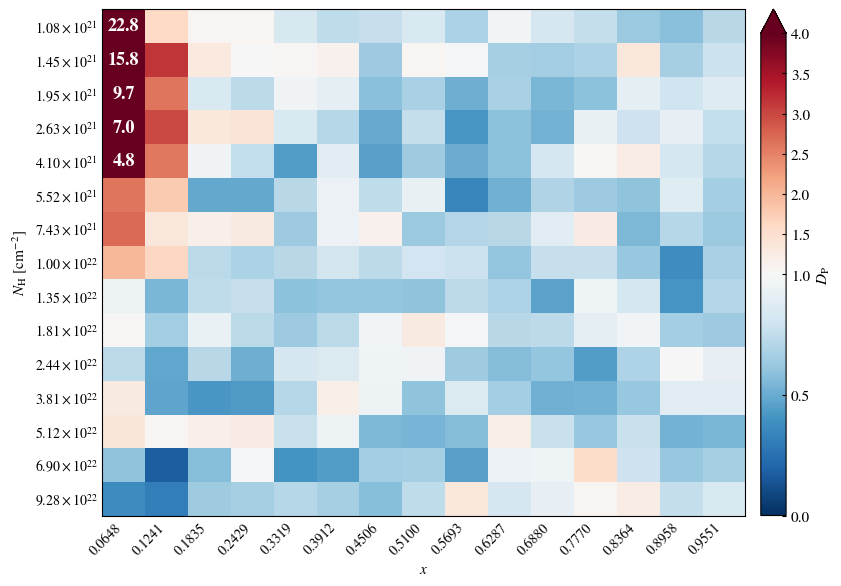

 Summary: Poisson-deviance grid
 Statistic           : radial two-sample Poisson deviance
 Grid                : 15 x 15  (225 cells, 225 finite, 0 missing)
 Annuli per image    : 24
 Mean D_red          : 1.4843
 Std (ddof=1)        : 2.9236     SEM: 0.1949
 Median D_red        : 1.0386
 Trimmed mean (10%)  : 1.0869
 Geometric mean      : 1.0944
 IQR                 : 0.8286 - 1.3420
 Percentiles         : p90=1.8169  p95=2.5801  p99=10.7684
 Min / Max           : 0.2507 / 31.5358
 Fraction D_red <= 1.00 :  45.33%  (102/225)
 Fraction D_red <= 2.00 :  92.44%  (208/225)
 Fraction D_red <= 3.00 :  95.56%  (215/225)
------------------------------------------------------------------
 Extremes
   Lowest       0.2507  at x=0.1241, nH=9.280e+22
   Highest     31.5358  at x=0.0648, nH=1.450e+21
   ~Mean        1.4778  at x=0.3319, nH=1.450e+21
   ~Median      1.0386  at x=0.6287, nH=1.950e+21
------------------------------------------------------------------
 Colour scale        : vmin=0, vma

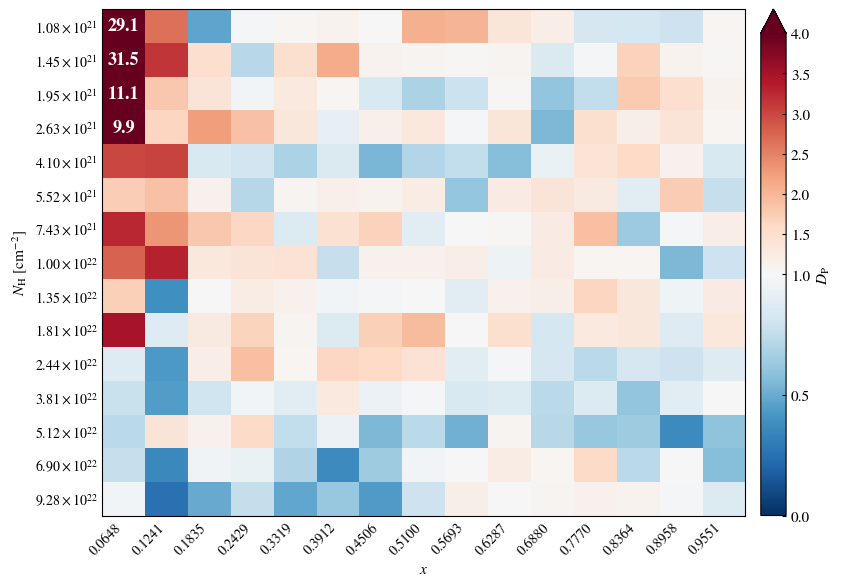

Bilinear interpolation   mean 1.09  median 0.75  std 1.96  max 22.8  cells>4:   5  cells<1: 179  mean outside x-column 1: 0.82
Model C 15k              mean 1.48  median 1.04  std 2.92  max 31.5  cells>4:   4  cells<1: 102  mean outside x-column 1: 1.11


In [65]:
# --- D_P heatmaps against the seed-287 test set: interpolation vs Model C 15k ---
hm_kwargs = dict(n_annuli=24, diverging=True, cmap="magma", figsize=(9, 6),
                 vmin=0.0, vmax=4.0, annotate_above=4, annotate_fontsize=13)

Heatmap_Interp, xs, nHs = poisson_deviance_heatmap_between_npz(
    npz_model_path=INTERP_NPZ, npz_data_path=REFLEX_NPZ, **hm_kwargs)
plt.show()
Heatmap_C15, xs, nHs = poisson_deviance_heatmap_between_npz(
    npz_model_path=f"{npz_dir}MODEL_C_15k.npz", npz_data_path=REFLEX_NPZ, **hm_kwargs)
plt.show()

for name, g in [("Bilinear interpolation", Heatmap_Interp), ("Model C 15k", Heatmap_C15)]:
    g = np.asarray(g, float)
    print(f"{name:24s} mean {g.mean():.2f}  median {np.median(g):.2f}  std {g.std():.2f}  "
          f"max {g.max():.1f}  cells>4: {(g > 4).sum():3d}  cells<1: {(g < 1).sum():3d}  "
          f"mean outside x-column 1: {g[:, 1:].mean():.2f}")


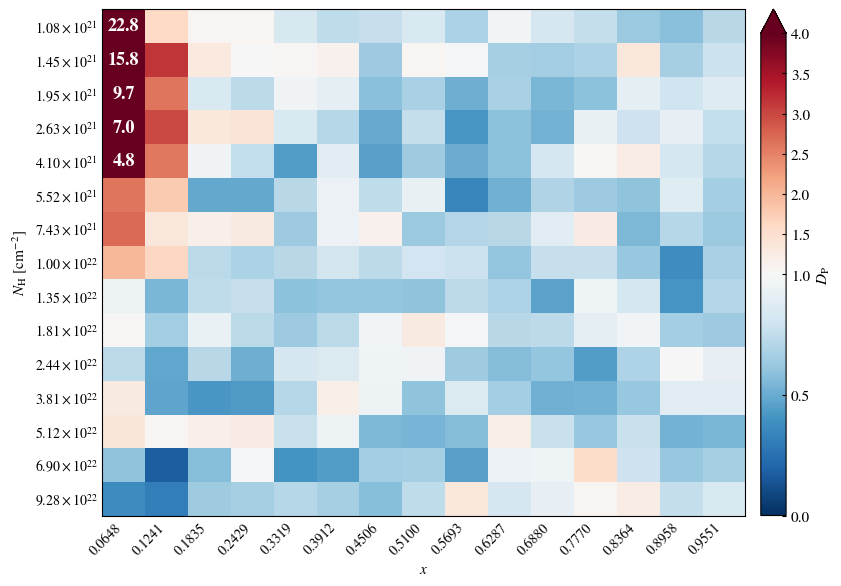

Bilinear interpolation         mean 1.09  median 0.75  outside x-column 1 0.82  x-column 1 4.91


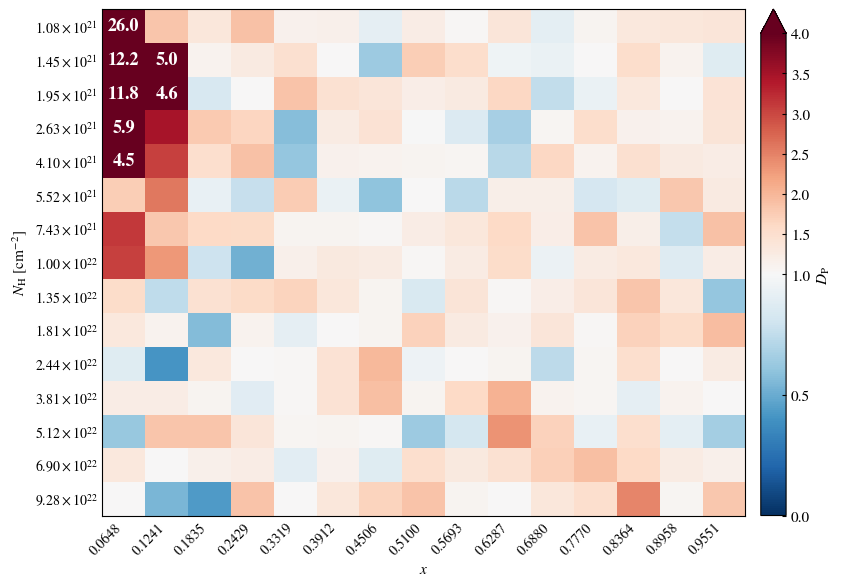

Interpolation + Poisson draw   mean 1.55  median 1.21  outside x-column 1 1.29  x-column 1 5.08


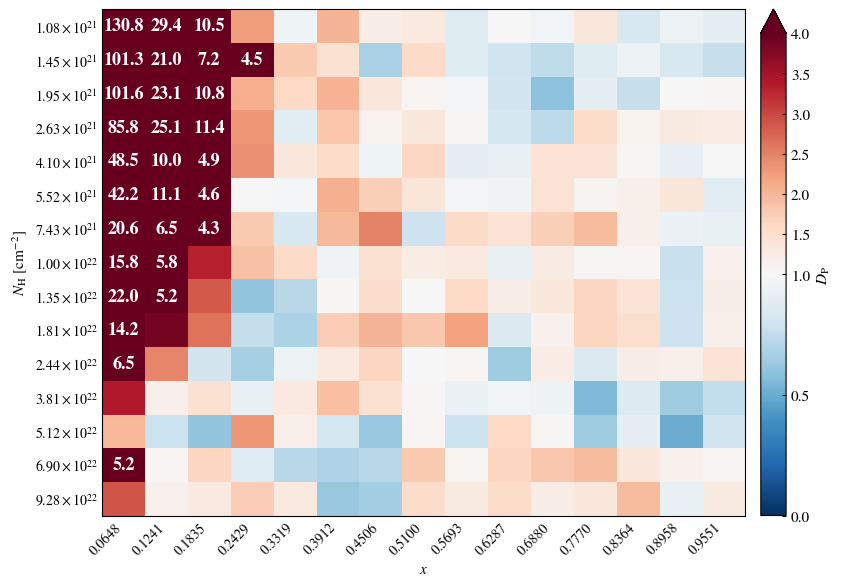

Nearest training image         mean 4.62  median 1.23  outside x-column 1 2.08  x-column 1 40.19


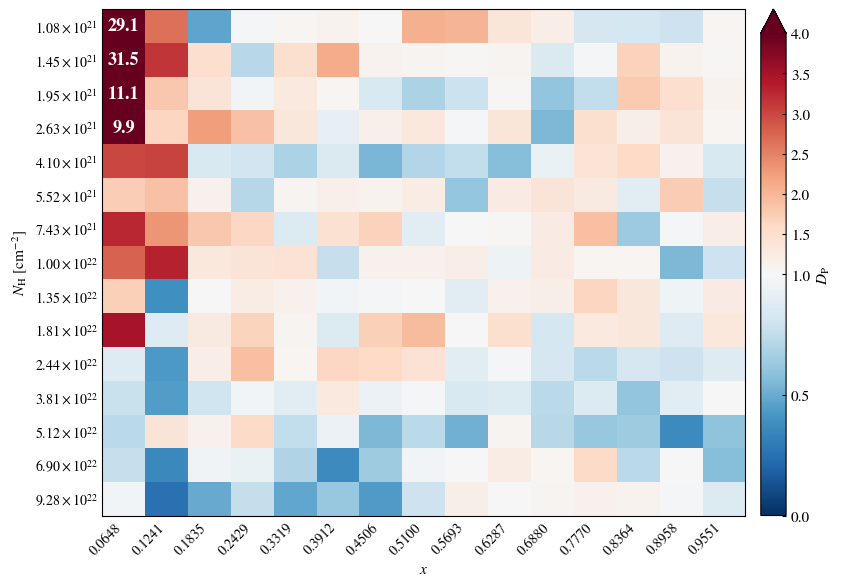

Model C 15k                    mean 1.48  median 1.04  outside x-column 1 1.11  x-column 1 6.77


In [66]:
# --- fairer baselines: interpolation as a *realization*, and nearest training image ---
# The bilinear image averages 4 Poisson images, so its noise variance is ~mu/4 (smoother than a
# realization) and its expected D_P against an independent realization is ~0.625, not 1.
rng = np.random.default_rng(0)
interp_pois = rng.poisson(np.clip(interp_mats, 0, None)).astype(np.float32)   # Poisson draw around the interpolated image
tl = np.log10(tr_nh)
nearest = np.array([tr_m[np.argmin(((tr_x - x) / 296.8) ** 2 + ((tl - np.log10(nh)) / 0.0645) ** 2)]
                    for x, nh in zip(te_x, te_nh)], dtype=np.float32)        # one real seed-42 image at a neighbouring condition
for name, mats in [("INTERP_POISSON", interp_pois), ("NEAREST", nearest)]:
    np.savez(f"{npz_dir}{name}_00k.npz", xs=te_x, nHs=te_nh, mats=mats,
             dmin=mats.min(axis=(1, 2)), dmax=mats.max(axis=(1, 2)), H=48, W=48)

rows = [("Bilinear interpolation", INTERP_NPZ), ("Interpolation + Poisson draw", f"{npz_dir}INTERP_POISSON_00k.npz"),
        ("Nearest training image", f"{npz_dir}NEAREST_00k.npz"), ("Model C 15k", f"{npz_dir}MODEL_C_15k.npz")]
import io, contextlib
for name, path in rows:
    with contextlib.redirect_stdout(io.StringIO()):
        g, _, _ = poisson_deviance_heatmap_between_npz(npz_model_path=path, npz_data_path=REFLEX_NPZ, **hm_kwargs)
    plt.close("all"); g = np.asarray(g, float)
    print(f"{name:30s} mean {g.mean():.2f}  median {np.median(g):.2f}  outside x-column 1 {g[:, 1:].mean():.2f}  x-column 1 {g[:, 0].mean():.2f}")
